# E115 · The last bag of fertiliser: 74 years of Broadbalk wheat and the weather of the year

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: grain yields of winter wheat on the Broadbalk field at Rothamsted, 1852-1925, 17 strips x 74 years (1,258 rows), from Lawes & Gilbert's records as published by Andrews & Herzberg (1985, *Data*, Springer) and distributed in the `agridat` R package (Kevin Wright; **MIT licence**). The treatment of every strip in every year is hand-coded from the early-period factor tables of the Electronic Rothamsted Archive (e-RA, era.rothamsted.ac.uk/Broadbalk). Credit: **Rothamsted Research and the e-RA**. Built by `tools/build_e115_broadbalk.py`; 1,102 strip-years are used. Present-day price ratios from AHDB (RB209 and its 2022 price notes) |
| **You will learn** | A **nonlinear mechanistic dose-response** model (Mitscherlich) with a latent **multiplicative year effect** written as a stationary AR(1) through its exact lower factor · a latent **soil nitrogen supply** that runs down, manure that builds up, carry-over that does not happen · prior predictive checks on the scale of a harvest · **Liebig's law of the minimum** tried literally, and a "partial Liebig" that beats it by about 145 points of elpd · **unreplicated strips** as shrunk strip effects (Fisher's point) · a **spread check** that finds the year changing the dose response and some strips noisier than others, and a year-by-dose term and per-strip noise that fix it · quadratic-plateau against Mitscherlich by **PSIS-LOO**, and a sharp linear-plateau that splits chains with zero divergences · a **decision layer**: average-year returns (inference) against one-year returns (prediction), the **economic optimum N rate** as a posterior, and where it leaves the data · for the public: **prediction beside inference** as paired 50-dot quantile dotplots, dotplot columns by kind of year, gradient intervals and a price-dial **GIF** |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: one BLAS pool per chain would fight

import logging
import sys
import textwrap
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import xarray as xr
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm
from scipy import optimize, stats

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 115
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO
BAG = 48  # kg N per hectare in one "bag" (one dose, N1, on Broadbalk)


def wrap(text, width=90):
    return "\n".join(textwrap.fill(t, width) for t in text.split("\n"))


print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** A farmer already spreads two bags of nitrogen on a hectare of wheat. Does a
third bag pay for itself, and how much does the weather of the year matter?

**What we did.** We used 74 years (1852-1925) of the world's oldest field experiment, where
strips of one field have had none, one, two, three or four doses of nitrogen. A model separates
what the fertiliser does from what each year's weather does to the whole field and to its
response to nitrogen, and lets each strip have its own soil without letting one strip decide.

**What we found.** On this Victorian wheat, a quarter of a modern crop, the third bag added about
460 kg of grain per hectare in an average year, well over the 240 kg of grain a bag costs at
today's usual price ratio. In a given year it paid less often: the weather alone would have left
it paying about 9 times in 10, and on one plot, where lodging, pests and the harvest add their
own luck, about 8 times in 10. A modern crop has a different curve, so the numbers are a lesson
in how to ask the question, not a recommendation.

**How sure are we.** It is *virtually certain* (>99%) that a third 48 kg bag pays for itself in an average year when nitrogen costs 5 kg of grain per kg. We have *medium confidence* in that figure: every curve and model we tried agrees, but each dose was tried on one unreplicated strip, and this is the wheat and soil of 1852-1925, not of today. On any single small plot in a single year it paid about 8 times in 10 (79%), a figure that depends on how the model treats plot-to-plot noise.

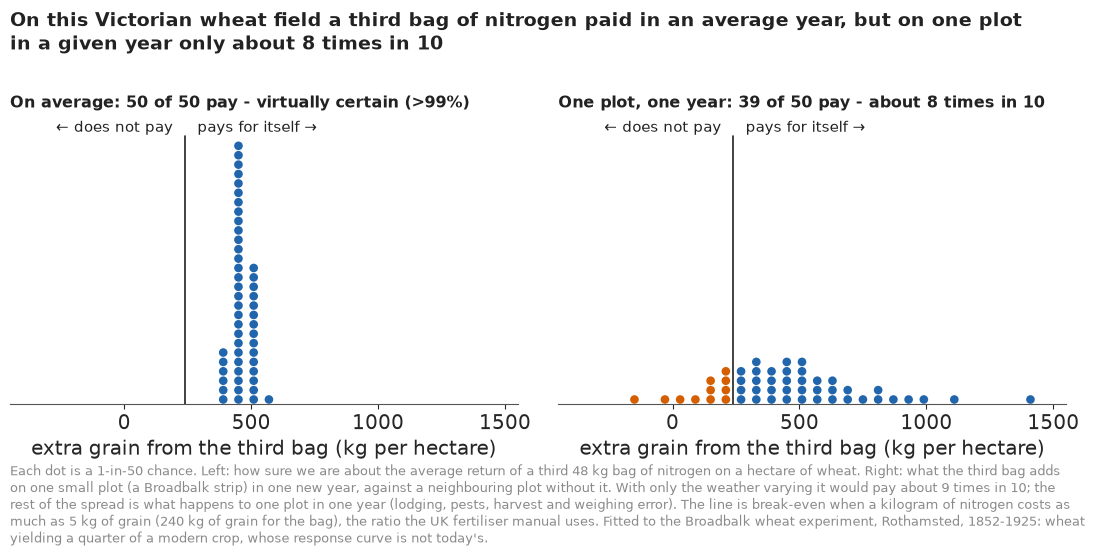

In [2]:
HOW_SURE = display(Markdown("**How sure are we.** *Filled in from the fits in part G.*"),
                   display_id=True)
HEADLINE = display(Markdown("*The headline figure is drawn in part G from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

In the autumn of 1843 John Bennet Lawes and Joseph Henry Gilbert sowed wheat on a field at
Rothamsted, north of London, and kept sowing it, year after year, on the same strips with the
same fertilisers. By 1852 the scheme had settled: one strip that never gets anything, one with
phosphorus, potassium, sodium and magnesium but no nitrogen, strips with one, two and three doses
of nitrogen on top of those minerals, strips with nitrogen but some minerals left out, and one
strip with farmyard manure. Broadbalk is still running, the oldest continuous field experiment in
the world (Johnston & Poulton 2018, *European Journal of Soil Science*). This notebook uses its
first 74 years, 1852-1925, the part of the record that Andrews & Herzberg (1985) printed in their
collection of datasets.

The same records are where modern statistics started. R. A. Fisher arrived at Rothamsted in 1919
and his first studies of "crop variation" were of these yields (Fisher 1921, *Journal of
Agricultural Science*); his 1924 paper on the influence of rainfall on the yield of wheat used
them too. What he found, a field whose every strip rises and falls together from year to year, and
strips that differ in ways the treatments do not explain, led him to replication and
randomisation (Fisher 1926). Both features matter here.

The question is the oldest in agronomy. Each extra kilogram of nitrogen adds less grain than the
one before (Mitscherlich 1909 wrote the law of diminishing returns as an exponential approach to
a ceiling), so somewhere the last bag stops paying for itself. Where depends on the price of
nitrogen against the price of wheat, and on the curve: Cerrato & Blackmer (1990) showed that
Mitscherlich, quadratic-plateau and linear-plateau curves fit the same maize trials about
equally well and put the economic optimum rate tens of kilograms apart. Liebig's law of the
minimum, that growth is limited by the scarcest nutrient, is the other old idea in play: some
Broadbalk strips got nitrogen without potassium for 74 years.

Two kinds of uncertainty meet in the decision: how sure we are about the *average* return of a
bag, which 74 years of data can pin down, and how much one *year* on one piece of field differs
from the average, which does not shrink with more data. Readers shown only the first kind
overestimate what a treatment will do for them (Hofman, Goldstein & Hullman 2020). The notebook
builds a model that gives both and ends with a picture that shows them side by side.

| part | question | tool |
|---|---|---|
| A | What does the field look like? | 74 years x 16 strips, raw increments per bag |
| B | What is a diminishing return? | Mitscherlich and two plateau curves, the price ratio |
| C | Can one curve and a year effect explain it? | the naive model, prior and posterior checks |
| D | Was Liebig right? | a literal law of the minimum against a partial one, potassium run-down |
| E | What do the strips themselves add? | strip effects, a spread check, year-by-dose, soil |
| F | Does the last bag pay? | average year against one year, the optimum N rate, curve choice |
| G | How do we explain it to everyone? | prediction beside inference, dotplot columns, a GIF |

## A · Seventy-four harvests on one field

The table has one row per strip and year: grain in tonnes per hectare at field moisture, and the
treatment that strip had that year, coded by `tools/build_e115_broadbalk.py` from the e-RA's
tables for the early period. One dose (N1) is 48 kg of nitrogen per hectare, so N2, N3 and N4
are 96, 144 and 192. Until 1877 the ammonium salts went on in autumn, in 1878-83 in spring, and
from 1884 split between the two; strip 9 got sodium nitrate in spring from 1894.

In [3]:
data.describe("e115_broadbalk")
RAW = data.load("e115_broadbalk")
print(f"{len(RAW):,} rows, years {RAW.year.min()}-{RAW.year.max()}, "
      f"{RAW['plot'].nunique()} strips, "
      f"missing grain: {int(RAW.grain.isna().sum())}")
print(RAW.groupby("use").size().rename({0: "not used", 1: "used"}).to_string())

e115_broadbalk: One row per plot and year (1,258 rows, 17 plots x 74 years): year, plot (P02 = strip 2b ... P19), grain, straw (t/ha at field moisture, about 85% dry matter), n_kg (fertiliser N for that crop, kg N/ha: N1 48, N2 96, N3 144, N4 192), n_form (amm = ammonium salts, nit = sodium nitrate, none), n_timing (autumn, spring, split or none: ammonium all autumn 1852-77, spring 1878-83, split 1884-1925; strip 15 spring 1873-77 and autumn 1878-1925; nitrate in spring), p, k, na, mg (1 if applied that year; all omitted 1915 and K 1917-19; strips 12 and 14 get the larger Na* and Mg* dressings, coded 1), fym (strip 2b, 35 t/ha, about 225 kg N), rape (strip 19, rape cake), minerals_last_year (alternating strips 17/18 in their N year), n_last_year (kg N the year before), use (0 for strip 9 before 1894 and strip 15 before 1873, whose halves were treated differently, and for strip 19), note (treatment phase). Strip 16: N4 PKNaMg 1852-64, nil 1865-83, N2* PKNaMg 1884-1925.
  source: Broadba

We leave out what the record cannot describe: strip 9 before 1894 and strip 15 before 1873 (two
halves treated differently), strip 19 (rape cake, an organic nitrogen we cannot calibrate), and
strip 16's unfertilised years 1865-83, whose soil carried thirteen years of the heaviest
dressing. The wartime omissions of minerals (1915, potassium in 1917-19) are ignored, since a
soil's reserves carry over a year. On the alternating strips 17 and 18 (nitrogen one year,
minerals the next) the nitrogen year counts as fully mineralised.

In [4]:
reg = (RAW[RAW.year < 1915].groupby(["plot", "note"])[["p", "k", "na", "mg"]].max().reset_index())
D = (RAW[(RAW.use == 1) & ~RAW.note.str.startswith("nil 1865")]
     .drop(columns=["p", "k", "na", "mg"]).merge(reg, on=["plot", "note"], how="left"))
D.loc[D.minerals_last_year == 1, ["p", "k", "na", "mg"]] = 1
D = D.sort_values(["year", "plot"]).reset_index(drop=True)
YEARS = np.arange(1852, 1926)
D["t"] = D.year - 1852
print(f"{len(D):,} strip-years used, {D["plot"].nunique()} strips")
print(D.groupby("note").agg(strip=("plot", "first"), years=("year", "size"),
                            mean_grain=("grain", "mean"), n_kg=("n_kg", "first"))
      .sort_values("mean_grain").round(2).to_string())

1,102 strip-years used, 16 strips
                                        strip  years  mean_grain  n_kg
note                                                                  
nil                                       P03     74        0.85     0
PKNaMg                                    P05     74        0.98     0
PKNaMg year (N2 last year)                P18     74        1.02     0
N2                                        P10     74        1.39    96
N2 P                                      P11     74        1.56    96
N1 PKNaMg                                 P06     74        1.57    48
N1* PKNaMg                                P09     32        1.80    48
N2 PKNaMg, N timing differs from plot 7   P15     53        1.89    96
N2 P Mg                                   P14     74        1.95    96
N2 P Na                                   P12     74        1.98    96
N2 year (minerals last year)              P17     74        2.02    96
N2 P K                                    P

Wheat in this period yields between about 0.85 t/ha with nothing and 2.5 t/ha with three doses or
manure, about a quarter of a modern crop, in line with the 1-2.5 t/ha Johnston & Poulton give for
the early decades. The opening picture puts the whole record on one page: one row per strip,
one column per harvest.

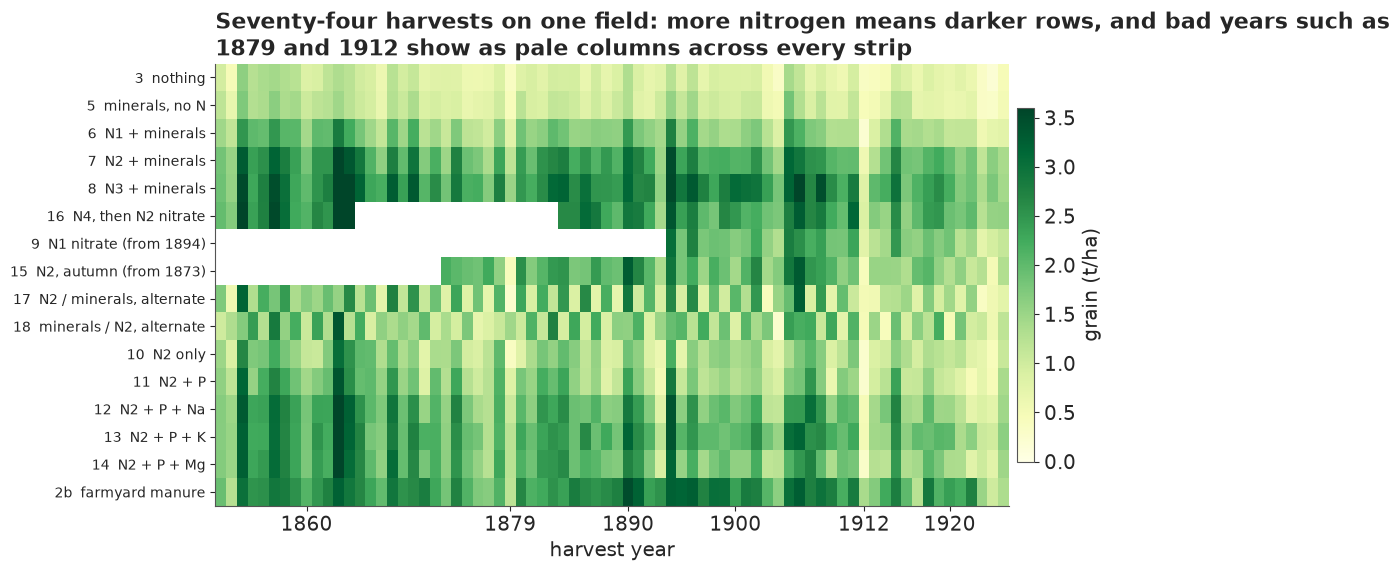

In [5]:
ORDER = ["P03", "P05", "P06", "P07", "P08", "P16", "P09", "P15", "P17", "P18",
         "P10", "P11", "P12", "P13", "P14", "P02"]
LABEL = {"P03": "3  nothing", "P05": "5  minerals, no N", "P06": "6  N1 + minerals",
         "P07": "7  N2 + minerals", "P08": "8  N3 + minerals", "P16": "16  N4, then N2 nitrate",
         "P09": "9  N1 nitrate (from 1894)", "P15": "15  N2, autumn (from 1873)",
         "P17": "17  N2 / minerals, alternate", "P18": "18  minerals / N2, alternate",
         "P10": "10  N2 only", "P11": "11  N2 + P", "P12": "12  N2 + P + Na",
         "P13": "13  N2 + P + K", "P14": "14  N2 + P + Mg", "P02": "2b  farmyard manure"}
M = D.pivot_table(index="plot", columns="year", values="grain").reindex(ORDER)
fig, ax = plt.subplots(figsize=(11, 5.6))
im = ax.imshow(np.ma.masked_invalid(M.to_numpy()), aspect="auto", cmap="YlGn", vmin=0, vmax=3.6,
               extent=(1851.5, 1925.5, len(ORDER) - 0.5, -0.5), interpolation="nearest")
ax.set_yticks(range(len(ORDER)), [LABEL[p] for p in ORDER], fontsize=10)
ax.set_xlabel("harvest year")
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01)
cb.set_label("grain (t/ha)")
ax.set_xticks([1860, 1879, 1890, 1900, 1912, 1920])
ax.set_title(wrap("Seventy-four harvests on one field: more nitrogen means darker rows, and bad "
                  "years such as 1879 and 1912 show as pale columns across every strip", 90),
             loc="left");

Two patterns jump out. Rows differ by treatment, and darker rows go with more nitrogen and full
minerals. Columns differ by year, and a bad year is pale on every strip at once: 1879, a
notoriously cold and wet summer, and 1912 stand out. Everything also fades from left to right,
as soils that get no manure lose the reserves they started with. The model has to carry all
three: a dose response, a year that lifts or sinks the whole field, and slow change in the soil.

### What the strips say before any model

Strips 5, 6, 7 and 8 get the same minerals and 0, 1, 2 and 3 doses of nitrogen every year, so
their year-by-year differences are the raw return to each extra bag. Strip 16 had a fourth dose
in 1852-64 only.

In [6]:
W = D.pivot_table(index="year", columns="plot", values="grain")
INC = pd.DataFrame({"bag 1": W.P06 - W.P05, "bag 2": W.P07 - W.P06, "bag 3": W.P08 - W.P07})
print("extra grain per bag (kg/ha), mean and sd over the 74 years:")
print((INC.agg(["mean", "std"]) * 1000).round(0).to_string())
P_RAW3 = float((INC["bag 3"] > 0.240).mean())
print(f"bag 3 added more than 240 kg in {P_RAW3:.0%} of years "
      f"({int((INC['bag 3'] > 0.240).sum())} of {len(INC)})")
print("bag 3 by period (kg):", {p: round(1000 * INC["bag 3"][m].mean())
                                for p, m in (("1852-77", INC.index <= 1877),
                                             ("1878-1925", INC.index > 1877))})
b4 = (W.P16 - W.P08).loc[1852:1864]
RAW4 = 1000 * b4.mean()
print(f"bag 4 (strip 16 - strip 8, 1852-64): {RAW4:.0f} kg, sd {1000 * b4.std():.0f}, "
      f"standard error {1000 * b4.std() / np.sqrt(len(b4)):.0f}, {len(b4)} years")

extra grain per bag (kg/ha), mean and sd over the 74 years:
      bag 1  bag 2  bag 3
mean  591.0  645.0  313.0
std   257.0  204.0  245.0
bag 3 added more than 240 kg in 61% of years (45 of 74)
bag 3 by period (kg): {'1852-77': 248, '1878-1925': 348}
bag 4 (strip 16 - strip 8, 1852-64): 50 kg, sd 109, standard error 30, 13 years


The first bag adds about 590 kg, the second about 650 and the third about 310; the year-to-year
spread of each is about 250 kg. That the second bag beats the first already says something: no
smooth curve with diminishing returns can do it, so either the response really is S-shaped at
low doses or the strips themselves differ. Fisher's answer was the second, and our model in
part E partly agrees, though with one strip per dose the data cannot rule out the first.
The third bag cleared 240 kg of grain (the break-even we will meet in part B) in 61% of the
years, and the fourth bag, tried for only thirteen years, added about 50 kg, give or take 30.

## B · Diminishing returns

### Three curves

Let $x$ be the nitrogen available to the crop (fertiliser plus what the soil supplies) and $Y$
the yield. **Mitscherlich's** curve approaches a ceiling $A$ exponentially,

$$ Y = A\,\bigl(1 - e^{-c x}\bigr), \qquad \frac{dY}{dx} = c\,(A - Y), $$

so each kilogram adds a fixed fraction of what is still missing: diminishing returns at every
dose, with no dose where they stop. The **quadratic-plateau** curve $Y = A\,[1 - (1 - \min(bx,
1))^2]$ rises as a parabola and reaches its ceiling exactly at $x = 1/b$; the
**linear-plateau** $Y = A \min(bx, 1)$ has no diminishing returns at all until it hits the wall.
Inside the range of doses tried, all three can fit; beyond it, they tell different stories.

### The price of a bag

A bag of 48 kg N pays for itself if it adds more grain than it costs. With nitrogen at $p_N$ per
kg and grain at $p_Y$ per kg, the **break-even ratio** $R = p_N / p_Y$ is the number of kg of
grain one kg of nitrogen costs, so the bag pays if it adds more than $48R$ kg of grain. The
economic optimum rate (EONR) is where the curve's slope falls to $R$. The UK's fertiliser
manual, AHDB's RB209, sets its cereal recommendations at $R = 5$, so a bag must add 240 kg. In
the 2022 price spike AHDB's own example (ammonium nitrate at £522 per tonne against wheat at
£182) gave about 8. We use $R = 5$ for the headline and let $R$ run from 4 to 12 as a dial. We
do not pretend to know nineteenth-century prices: the question is what this field's biology
would have said at today's ratios.

Before any Bayesian model, the three curves fitted by least squares to the four strips' century
averages show the problem.

            shape  sse  soil_N  bag3  bag4  EONR_R5
     Mitscherlich 8848      54   407   318    224.0
quadratic-plateau 7474      56   390   251    173.0
   linear-plateau  487      75   322     0    122.0


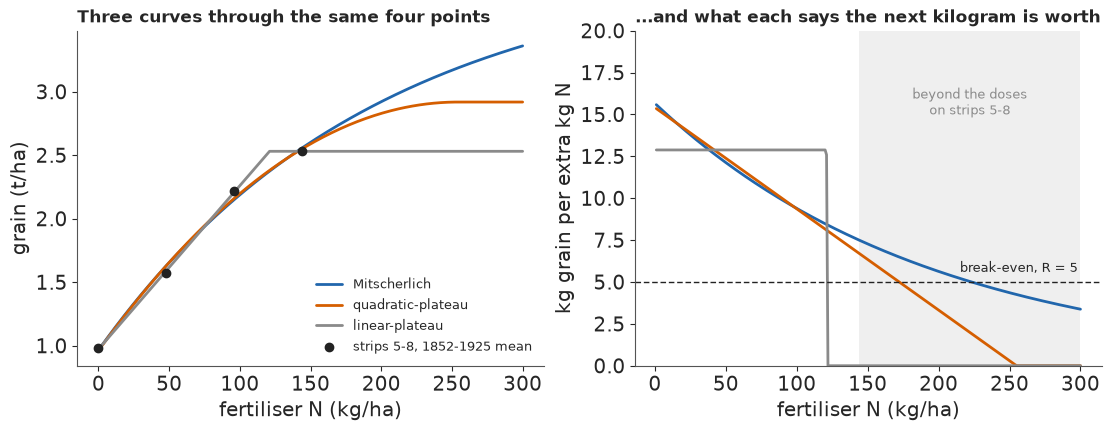

In [7]:
NX = np.array([0, 48, 96, 144.0])
YX = np.array([W[p].mean() for p in ("P05", "P06", "P07", "P08")])
SHAPES = {"Mitscherlich": lambda x, b: 1 - np.exp(-b * x),
          "quadratic-plateau": lambda x, b: 1 - (1 - np.minimum(b * x, 1)) ** 2,
          "linear-plateau": lambda x, b: np.minimum(b * x, 1)}


def ls_fit(shape):
    """Least-squares (A, b, soil N) for one shape, best of a few starts."""
    def loss(th):
        A, b, s = np.exp(th)
        return np.sum((A * SHAPES[shape]((NX + s) / 100, b) - YX) ** 2)
    starts = [np.log([a, b, s]) for a in (2.6, 3.2) for b in (0.3, 0.6, 1.0) for s in (30, 60)]
    best = min((optimize.minimize(loss, s0, method="Nelder-Mead",
                                  options=dict(xatol=1e-8, fatol=1e-12, maxiter=8000))
                for s0 in starts), key=lambda r: r.fun)
    return np.exp(best.x), best.fun


NG = np.arange(0, 301.0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
rows = []
for (shape, f), col in zip(SHAPES.items(), (HI, LO, MUTED)):
    (A, b, s), sse = ls_fit(shape)
    y = 1000 * A * f((NG + s) / 100, b)
    a1.plot(NG, y / 1000, color=col, lw=2, label=shape)
    a2.plot(NG[1:], np.diff(y), color=col, lw=2)
    bags = 1000 * A * f((np.array([0, 48, 96, 144, 192]) + s) / 100, b)
    slope = np.diff(y)
    eonr = NG[1:][np.argmax(slope < 5)] if (slope < 5).any() else np.nan
    rows.append(dict(shape=shape, sse=round(sse * 1e6), soil_N=round(s),
                     bag3=round(bags[3] - bags[2]),
                     bag4=round(bags[4] - bags[3]), EONR_R5=eonr))
a1.scatter(NX, YX, color=INK, zorder=4, label="strips 5-8, 1852-1925 mean")
a1.legend(fontsize=9.5, loc="lower right")
a1.set_xlabel("fertiliser N (kg/ha)")
a1.set_ylabel("grain (t/ha)")
a1.set_title("Three curves through the same four points", loc="left", fontsize=12)
a2.axhline(5, color=INK, lw=1, ls=(0, (4, 2)))
a2.text(298, 5.6, "break-even, R = 5", ha="right", fontsize=9.5)
a2.axvspan(144, 300, color=LIGHT, alpha=0.4, lw=0)
a2.text(222, 15, "beyond the doses\non strips 5-8", ha="center", fontsize=9.5, color=MUTED)
a2.set_ylim(0, 20)
a2.set_xlabel("fertiliser N (kg/ha)")
a2.set_ylabel("kg grain per extra kg N")
a2.set_title("...and what each says the next kilogram is worth", loc="left", fontsize=12);
print(pd.DataFrame(rows).to_string(index=False))

Inside the doses tried the three curves lie almost on top of each other: the root mean square
miss is under 50 kg for every shape (the `sse` column is in kg²), and the linear-plateau, which
can put its corner anywhere, fits best. Their slopes do not agree. Mitscherlich's slope falls
smoothly and crosses $R = 5$ at about 225 kg N, far past the last dose; the quadratic-plateau's
falls in a straight line and crosses at about 175; the linear-plateau keeps its slope and then
stops dead at about 120. The fourth bag is worth about 320, 250 or 0 kg depending on the shape,
and the "optimum" rate moves with it. With four points we cannot tell the shapes apart; part F
asks whether 1,102 strip-years can.

## C · Year and dose: a first model

### The model

For strip $p$ in year $t$ with yield $y_{pt}$,

$$ \log y_{pt} \sim \text{Student-}t\bigl(\nu,\ \log \mu_{pt},\ \sigma\bigr), \qquad
   \mu_{pt} = A_t \; f(x_{pt}) \; e^{-\text{pen}_{pt}}, $$

with these parts.

**The year potential** $A_t$ is the ceiling the weather of year $t$ allows, the same for every
strip: $\log A_t = a_0 + \eta_t$, where $\eta$ is a stationary AR(1) with marginal sd $s_\eta$ and
lag-one correlation $\phi$, since a good year for the soil may help the next. We write it
non-centred: with $z_t \sim N(0, 1)$, $\eta = s_\eta \sqrt{1-\phi^2}\, L\, (\text{scale}\cdot z)$,
where $L_{ij} = \phi^{\,i-j}$ for $i \ge j$ is the exact lower factor of the AR(1) recursion and
the first $z$ is scaled by $1/\sqrt{1-\phi^2}$. That is one $74 \times 74$ product per gradient
and no `scan`. A year effect that multiplies the curve says a good year helps a heavily fertilised
strip more, in kilograms, than an unfertilised one: the shape of the response is the same every
year, its height is not (part E relaxes this).

**The nitrogen available** is, in units of 100 kg N/ha,

$$ x_{pt} = N_{pt}\, e_{\text{nit}}^{[\text{nitrate}]}\, e_{\text{aut}}^{[\text{autumn}]}
    + \rho N_{p,t-1} + N_s(t)
    + [\text{manure}]\; n_{\text{man}} \bigl(1 - e^{-(t-1843)/\tau_m}\bigr). $$

Fertiliser counts in full if it is ammonium in spring or split; sodium nitrate and autumn
ammonium get their own efficiencies. A share $\rho$ of last year's dose may still be there (only
strips 17 and 18 can tell). The soil supplies $N_s(t) = n_\infty + n_{\text{gap}}
e^{-(t-1852)/\tau_s}$, running down from what the old grassland left towards a settled level,
and the manure strip builds up organic nitrogen from 1843 on.

**The curve** $f$ is Mitscherlich, $1 - e^{-cx}$, unless we say otherwise.

**Missing minerals** multiply the yield by $e^{-\text{pen}}$, with penalties that grow linearly
over the 74 years as the soil's reserves run down: $\lambda_P(t)$ without phosphorus,
$\lambda_K(t)$ without potassium (softened by shares $w_{\text{Na}}$ and $w_{\text{Mg}}$ when
sodium or magnesium is given, which can partly stand in for potassium), and a small
$\lambda_{\text{NaMg}}$ for potassium without sodium and magnesium.

**The error** is Student-t on the log scale, because some strip-years are wrecked by lodging,
disease or birds and a normal error would bend the whole fit to them.

### Priors on the scale of a harvest

$a_0 \sim N(\log 3, 0.4)$ puts the ceiling of an average year near 3 t/ha, with 1.4-6 t/ha
plausible for Victorian wheat. $c \sim \text{LogNormal}(0, 0.5)$ per 100 kg puts the dose that
reaches half the ceiling near 70 kg N, the middle of what agronomists report. $s_\eta \sim
\text{HalfNormal}(0.4)$ lets a year move the ceiling by a third or so; $\phi \sim \text{Beta}(2,
2)$; soil supply $n_\infty \sim \text{LogNormal}(\log 0.3, 0.6)$ (30 kg) and a start-up excess
$n_{\text{gap}} \sim \text{LogNormal}(\log 0.2, 0.8)$ fading over $\tau_s \sim
\text{LogNormal}(\log 15, 0.6)$ years; efficiencies $\text{LogNormal}(0, 0.3)$; carry-over $\rho
\sim \text{Beta}(1, 6)$; manure $n_{\text{man}} \sim \text{LogNormal}(\log 1.5, 0.5)$ (150 kg)
over $\tau_m \sim \text{LogNormal}(\log 20, 0.7)$ years; penalties $\text{HalfNormal}(0.5)$;
$\sigma \sim \text{HalfNormal}(0.3)$ and $\nu \sim \text{Gamma}(2, 0.1)$.

One function builds every variant in the notebook: the curve (Mitscherlich, quadratic-plateau or
a smoothed linear-plateau with sharpness `kink`), how missing minerals act (`liebig`), and
whether strips get their own effects (`strips`, part E).

In [8]:
PLOTS = np.sort(D["plot"].unique())
STRIPS = PLOTS[PLOTS != "P02"]
COORDS = {"year": YEARS, "obs": np.arange(len(D)), "strip": STRIPS, "plot": PLOTS,
          "term": ["slope", "bend"]}
P_IDX = pd.Index(PLOTS).get_indexer(D["plot"])
assert (P_IDX >= 0).all() and PLOTS[0] == "P02"
T_IDX = D.t.to_numpy()
XN = D.n_kg.to_numpy() / 100.0
XN_LAST = D.n_last_year.to_numpy() / 100.0
NIT = (D.n_form == "nit").to_numpy() * 1.0
AUT = (D.n_timing == "autumn").to_numpy() * 1.0
FYM = D.fym.to_numpy() * 1.0
NO_P, NO_K = 1.0 - D.p.to_numpy(), 1.0 - D.k.to_numpy()
NA_, MG_ = D.na.to_numpy() * 1.0, D.mg.to_numpy() * 1.0
NO_NAMG = ((D.k == 1) & (D.na == 0) & (D.mg == 0)).to_numpy() * 1.0
S_TIME = D.t.to_numpy() / 73.0  # 0 in 1852, 1 in 1925
YR = D.year.to_numpy()
LOGY = np.log(D.grain.to_numpy())
LAG = np.subtract.outer(np.arange(len(YEARS)), np.arange(len(YEARS)))


def hx(n100):
    """Year-by-dose shapes of the dose n (100 kg N): a slope and a bend, centred near N2."""
    d = np.asarray(n100) - 1.0
    return np.stack([d, d**2 - 0.5], axis=-1)


HX = hx(XN)


def build(curve="mit", liebig="mult", strips=False, kink=12.0, q_min=6.0, noise=False):
    """Broadbalk response model. curve: mit | qp | lp; liebig: mult | min | partial.

    noise=True (part E): a year-by-dose term and a noise scale for each strip.
    """
    T = len(YEARS)
    with pm.Model(coords=COORDS) as m:
        a0 = pm.Normal("a0", np.log(3.0), 0.4)
        s_eta = pm.HalfNormal("s_eta", 0.4)
        phi = pm.Beta("phi", 2.0, 2.0)
        z = pm.Normal("z", 0, 1, dims="year")
        L = pt.switch(LAG >= 0, phi ** pt.maximum(LAG, 0), 0.0)
        scale0 = pt.concatenate([[1.0 / pt.sqrt(1 - phi**2)], pt.ones(T - 1)])
        eta = pm.Deterministic("eta", s_eta * pt.sqrt(1 - phi**2) * (L @ (scale0 * z)), dims="year")
        ns_inf = pm.LogNormal("ns_inf", np.log(0.3), 0.6)
        ns_gap = pm.LogNormal("ns_gap", np.log(0.2), 0.8)
        tau_s = pm.LogNormal("tau_s", np.log(15.0), 0.6)
        e_nit = pm.LogNormal("e_nit", 0.0, 0.3)
        e_aut = pm.LogNormal("e_aut", 0.0, 0.3)
        rho = pm.Beta("rho", 1.0, 6.0)
        nman = pm.LogNormal("nman", np.log(1.5), 0.5)
        tau_m = pm.LogNormal("tau_m", np.log(20.0), 0.7)
        x = (XN * (1 + (e_nit - 1) * NIT) * (1 + (e_aut - 1) * AUT) + rho * XN_LAST
             + ns_inf + ns_gap * pt.exp(-(YR - 1852) / tau_s)
             + FYM * nman * (1 - pt.exp(-(YR - 1843) / tau_m)))
        if curve == "mit":
            c = pm.LogNormal("c", 0.0, 0.5)
            f = 1 - pt.exp(-c * x)
        elif curve == "qp":
            b = pm.LogNormal("b", np.log(0.4), 0.5)
            f = pt.maximum(1 - (1 - pt.minimum(b * x, 1.0)) ** 2, 1e-6)
        else:  # linear-plateau, smoothed: -log(exp(-k b x) + exp(-k)) / k -> min(b x, 1)
            b = pm.LogNormal("b", np.log(0.6), 0.5)
            f = pt.maximum(-pt.log(pt.exp(-kink * b * x) + np.exp(-kink)) / kink, 1e-6)
        lamP = pm.HalfNormal("lamP", 0.5, shape=2)  # (in 1852, extra by 1925)
        lamK = pm.HalfNormal("lamK", 0.5, shape=2)
        w_na = pm.Beta("w_na", 2, 2)
        w_mg = pm.Beta("w_mg", 2, 2)
        lamNM = pm.HalfNormal("lamNaMg", 0.2)
        pen = (NO_P * (lamP[0] + lamP[1] * S_TIME)
               + NO_K * (1 - w_na * NA_) * (1 - w_mg * MG_) * (lamK[0] + lamK[1] * S_TIME)
               + NO_NAMG * lamNM)
        if liebig == "partial":  # a missing nutrient bites harder where nitrogen is plentiful
            gam = pm.HalfNormal("gam", 2.0)
            g = f * pt.exp(-pen * f**gam)
        elif liebig == "min":    # law of the minimum, smoothed: the scarcer of f and exp(-pen)
            g = (f**-q_min + pt.exp(q_min * pen) - 1) ** (-1 / q_min)  # exactly f when pen = 0
        else:
            g = f * pt.exp(-pen)
        logmu = a0 + eta[T_IDX] + pt.log(g)
        if noise:  # the year also changes what the dose does: zeta1_t h1 + zeta2_t h2
            s_z = pm.HalfNormal("s_zeta", 0.2, shape=2)
            zz = pm.ZeroSumNormal("zz", sigma=1.0, dims=("term", "year"))  # sums to 0 over years
            logmu = logmu + pt.sum((s_z[:, None] * zz).T[T_IDX] * HX, axis=1)
        if strips:  # every strip but the manure strip 2b gets its own soil, shrunk to the others
            s_u = pm.HalfNormal("s_u", 0.1)
            u = pm.ZeroSumNormal("u", sigma=s_u, dims="strip")
            logmu = logmu + pt.concatenate([pt.zeros(1), u])[P_IDX]
        sigma = pm.HalfNormal("sigma", 0.3)
        if noise:  # strip p's scale: sigma * exp(s_sig * zs_p), shrunk towards the common one
            s_sig = pm.HalfNormal("s_sig", 0.5)
            zs = pm.Normal("zs", 0, 1, dims="plot")
            sig_p = pm.Deterministic("sig_p", sigma * pt.exp(s_sig * zs), dims="plot")
            sigma = sig_p[P_IDX]
        nu = pm.Gamma("nu", 2.0, 0.1)
        pm.StudentT("logy", nu=nu, mu=logmu, sigma=sigma, observed=LOGY, dims="obs")
    return m


m_naive = build()

### Prior predictive check

Before fitting, we ask what harvests the priors imagine. A model that thinks 20 t/ha of wheat was
possible in 1870 has priors that are not doing their job.

In [9]:
with m_naive:
    prior = pm.sample_prior_predictive(1000, random_seed=RANDOM_SEED)
yprior = np.exp(prior.prior_predictive["logy"].values.reshape(-1, len(D)))
for lab, mask in (("nothing (strip 3)", (D["plot"] == "P03").to_numpy()),
                  ("N3 + minerals (strip 8)", (D["plot"] == "P08").to_numpy()),
                  ("all strip-years", np.ones(len(D), bool))):
    q = np.quantile(yprior[:, mask], [0.05, 0.5, 0.95])
    print(f"{lab:>25}: prior predictive 5/50/95%: {q[0]:.2f} / {q[1]:.2f} / {q[2]:.2f} t/ha")
print(f"share of prior strip-years above 10 t/ha: {np.mean(yprior > 10):.2%}; observed max "
      f"{D.grain.max():.2f}")

        nothing (strip 3): prior predictive 5/50/95%: 0.04 / 0.28 / 1.46 t/ha
  N3 + minerals (strip 8): prior predictive 5/50/95%: 0.80 / 2.49 / 7.49 t/ha
          all strip-years: prior predictive 5/50/95%: 0.21 / 1.48 / 5.51 t/ha
share of prior strip-years above 10 t/ha: 1.01%; observed max 4.10


The priors imagine strip 3 anywhere from almost nothing to about 1.5 t/ha and strip 8 at about
2.5 t/ha (0.8-7.5 in 90% of draws), with wide but finite tails: about 1% of imagined strip-years
are above 10 t/ha, which a Student-t with few degrees of freedom will always produce. Nothing in
the priors forces the answer, and nothing is absurd at the scale of the data.

### Fitting the naive model

Every fit uses nutpie with 4 chains, `target_accept=0.9` and 1,000 tuning steps rather than
nutpie's default 400, a margin for the one slow direction we meet below (800 for the main model
of part E, which adapts quickly). The main model keeps 1,000 draws per chain; the side fits keep
500, enough for LOO and for comparisons, at half the run time. A small helper fits, reports
diagnostics over every variable, and keeps only what later parts need: the LOO result and the
draws of a few scalars.

In [10]:
KEEP = ["a0", "s_eta", "phi", "sigma", "nu", "ns_inf", "ns_gap", "tau_s", "c", "b", "gam", "lamP",
        "lamK", "w_na", "w_mg", "lamNaMg", "eta", "u", "s_u", "e_nit", "e_aut", "rho", "nman",
        "tau_m", "s_zeta", "sig_p"]
LOOS, POST = {}, {}
SIDE = dict(draws=500)  # side fits: half the draws, enough for LOO and comparisons


def fit(model, name, tune=1000, draws=1000, **kw):
    t0 = time.time()
    with model:
        idata = pm.sample(draws=draws, tune=tune, random_seed=RANDOM_SEED, target_accept=0.9,
                          progressbar=False, **kw)
        pm.compute_log_likelihood(idata, progressbar=False)
    loo = az.loo(idata, pointwise=True)
    loo.log_weights = None
    del idata["log_likelihood"]
    LOOS[name] = loo
    po = idata.posterior
    POST[name] = {v: po[v].values.reshape(-1, *po[v].shape[2:]) for v in KEEP if v in po}
    rh = {v: float(az.rhat(po[v]).max()) for v in po.data_vars}
    es = {v: float(az.ess(po[v]).min()) for v in po.data_vars}
    worst = max(rh, key=rh.get)
    k = np.asarray(loo.pareto_k)
    TIMES[name] = time.time() - t0
    print(f"[{name}] {TIMES[name]:.0f} s, tuning {po.attrs.get('tuning_steps')}, divergences "
          f"{int(idata.sample_stats['diverging'].sum())}, worst r_hat {rh[worst]:.3f} ({worst}), "
          f"min bulk ESS {min(es.values()):.0f} ({min(es, key=es.get)}), elpd_loo {loo.elpd:.1f} "
          f"(se {loo.se:.1f}), Pareto k > 0.7: {int((k > 0.7).sum())}")
    return idata


def by_treatment(model, idata, label):
    """Observed and predicted geometric mean per treatment phase, and 89% coverage.

    Geometric means (exp of the mean log yield) compare like with like: exp of a Student-t with nu
    near 3 has no useful arithmetic mean. Returns the table, the rows and the replicated log yields.
    """
    with model:
        pp = pm.sample_posterior_predictive(idata, random_seed=1, progressbar=False)
    lrep = pp.posterior_predictive["logy"].values.reshape(-1, len(D))
    lo, hi = np.exp(np.quantile(lrep, [0.055, 0.945], axis=0))
    out = D[["plot", "year", "note", "grain"]].assign(cover=(D.grain >= lo) & (D.grain <= hi))
    codes, notes = pd.factorize(D.note)
    onehot = np.eye(len(notes))[codes] / np.bincount(codes)  # obs x phase, columns average
    pred = pd.Series(np.exp(np.median(lrep @ onehot, 0)), index=notes)
    tab = (out.assign(lg=LOGY).groupby("note")
           .agg(strip=("plot", lambda s_: ",".join(sorted(s_.unique()))), n=("grain", "size"),
                obs=("lg", lambda v: np.exp(v.mean())), cover89=("cover", "mean"))
           .assign(pred=pred).sort_values("obs").round(2))[["strip", "n", "obs", "pred", "cover89"]]
    print(f"{label}: overall 89% coverage {out.cover.mean():.2f}; obs and pred are geometric means")
    return tab, out, lrep


id_naive = fit(m_naive, "naive", **SIDE)
print(az.summary(id_naive, var_names=["a0", "s_eta", "phi", "c", "ns_inf", "lamK", "sigma", "nu"],
                 round_to=3).to_string())

[naive] 27 s, tuning 1000, divergences 0, worst r_hat 1.043 (eta), min bulk ESS 93 (eta), elpd_loo 350.7 (se 34.5), Pareto k > 0.7: 0
          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
a0       1.368  0.085     1.230     1.501    98.725   152.198  1.042      0.009    0.004
s_eta    0.309  0.031     0.266     0.359   208.502   323.082  1.004      0.002    0.002
phi      0.325  0.100     0.165     0.486   163.748   279.491  1.018      0.008    0.005
c        0.441  0.050     0.368     0.526   148.586   255.816  1.024      0.004    0.002
ns_inf   0.599  0.031     0.549     0.650   202.929   386.907  1.020      0.002    0.001
lamK[0]  0.150  0.025     0.110     0.190   824.851   930.252  1.003      0.001    0.001
lamK[1]  0.260  0.045     0.188     0.331   745.220   959.797  1.004      0.002    0.001
sigma    0.120  0.005     0.111     0.128  1712.944  1598.123  1.000      0.000    0.000
nu       3.185  0.358     2.643     3.781  1800.496  1674.453  1.

No divergences and every Pareto $k$ fine, but the sampler is only adequate: r_hat reaches about
1.04 and the slowest directions, $a_0$ (the ceiling) and the year potentials, have a bulk ESS of
about 100 of 2,000 draws, as in the other side fits (r_hat up to about 1.06, apart from the sharp
plateau of part F). A higher ceiling with a gentler curve fits almost as well as a lower one with
a steeper curve, so $a_0$ and $c$ slide along a ridge. Side-fit numbers are good to their
rounding, no finer. The year potential has an sd of about 0.31 on the log scale (a good year
lifts the ceiling by a third) with weak persistence. The residual sd is about 0.12 with $\nu$
near 3: heavy tails, the wrecked strip-years. The table below compares geometric means, since a
lognormal-like Student-t this heavy has no useful arithmetic mean.

Adequate sampling says nothing about whether the model is right. The test is whether it
reproduces each treatment.

In [11]:
TAB_NAIVE, _, LREP_NAIVE = by_treatment(m_naive, id_naive, "naive")
print(TAB_NAIVE.to_string())

naive: overall 89% coverage 0.91; obs and pred are geometric means
                                           strip   n   obs  pred  cover89
note                                                                     
nil                                          P03  74  0.79  0.72     0.81
PKNaMg                                       P05  74  0.92  0.97     0.91
PKNaMg year (N2 last year)               P17,P18  74  0.94  0.98     0.82
N2                                           P10  74  1.27  1.48     0.76
N2 P                                         P11  74  1.41  1.51     0.85
N1 PKNaMg                                    P06  74  1.48  1.54     0.96
N1* PKNaMg                                   P09  32  1.70  1.61     1.00
N2 PKNaMg, N timing differs from plot 7      P15  53  1.76  1.86     0.83
N2 P Mg                                      P14  74  1.83  1.84     0.96
N2 P Na                                      P12  74  1.85  1.85     0.96
N2 year (minerals last year)             P17,

Three treatments give it away. Strip 10 (nitrogen and nothing else) is predicted at about 1.48
t/ha against 1.27 observed, and only about three quarters of its years fall in their 89% bands.
The unfertilised strip is predicted too low, about 0.72 against 0.79. And the fourth dose, on
strip 16 in 1852-64, is predicted at about 3.1 t/ha against 2.7: the curve that fits doses 0-3
overshoots the only data beyond them. The penalty for missing minerals is one multiplier
whatever the nitrogen, which is too much where nitrogen is scarce and too little where it is
plentiful. That is Liebig's question.

## D · Was Liebig right?

### The law of the minimum, literally

Justus von Liebig (after Carl Sprengel) taught that a crop's growth is set by the scarcest
nutrient: add nitrogen to a crop short of potassium and nothing happens. In our notation the
yield is the *minimum* of what the nitrogen allows and what the minerals allow,
$\min\bigl(f(x), e^{-\text{pen}}\bigr)$. A hard minimum has a kink; we smooth it as
$(f^{-q} + e^{\,q\,\text{pen}} - 1)^{-1/q}$ with $q = 6$, which is exactly $f$ when no mineral is
missing, close to the minimum once one is, and differentiable.
Paris (1992) argued that von Liebig's plateau models fit crop data as well as smooth ones.

### A partial law of the minimum

Between "multiply" and "minimum" there is a family:

$$ g = f(x)\, \exp\!\bigl(-\text{pen}\; f(x)^{\gamma}\bigr). $$

With $\gamma = 0$ it is the naive multiplier. With large $\gamma$ the penalty bites only where
nitrogen has lifted the crop near its ceiling, which is what a minimum does. We let the data
choose $\gamma \sim \text{HalfNormal}(2)$.

In [12]:
m_min = build(liebig="min")
id_min = fit(m_min, "Liebig minimum", **SIDE)
del id_min
m_part = build(liebig="partial")
id_part = fit(m_part, "partial Liebig", **SIDE)
print(az.summary(id_part, var_names=["gam", "lamK", "lamP", "w_na", "w_mg", "c"], round_to=3)
      .to_string())
print(az.compare({k: LOOS[k] for k in ("naive", "Liebig minimum", "partial Liebig")}, round_to=1)
      [["elpd", "elpd_diff", "dse", "p"]].to_string())

[Liebig minimum] 26 s, tuning 1000, divergences 0, worst r_hat 1.046 (eta), min bulk ESS 114 (a0), elpd_loo 221.9 (se 37.6), Pareto k > 0.7: 0


[partial Liebig] 27 s, tuning 1000, divergences 0, worst r_hat 1.051 (a0), min bulk ESS 82 (a0), elpd_loo 366.8 (se 34.3), Pareto k > 0.7: 0
          mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
gam      0.512  0.081     0.384     0.641   492.581   581.818  1.003      0.004    0.004
lamK[0]  0.282  0.056     0.199     0.373   410.061   598.949  1.008      0.003    0.002
lamK[1]  0.366  0.079     0.247     0.494   212.735   329.101  1.014      0.005    0.003
lamP[0]  0.047  0.032     0.005     0.104   326.149   255.592  1.007      0.001    0.001
lamP[1]  0.018  0.018     0.001     0.052  1424.504   904.749  0.999      0.000    0.001
w_na     0.728  0.062     0.629     0.829  2228.018  1324.671  1.000      0.001    0.001
w_mg     0.716  0.061     0.619     0.811  2143.473  1458.851  1.002      0.001    0.001
c        0.348  0.051     0.268     0.429    85.130    82.221  1.044      0.005    0.003
                 elpd  elpd_diff   dse      p
partial Lieb

The literal law of the minimum is much worse than the naive multiplier, by about 130 points of
expected log predictive density (elpd), several times its standard error. The reason is in the
first table of part A: with no nitrogen fertiliser, the strip without minerals (0.85 t/ha) and the
strip with full minerals (0.98) differ. A strict minimum says that where nitrogen is scarce,
minerals cannot matter, and the data say they do. The partial version beats the naive one by
about 16 points (standard error about 6), with $\gamma$ around 0.5: missing potassium bites harder
on a well-fed crop, but not only there. Liebig was half right.

The penalty for missing potassium grows over the 74 years, the visible signature of a soil
running out. The next figure shows the fitted curves in the first and last decade, for an average
strip, against the strips' decade means.

1852-1861: yield lost without K at 96 / 144 / 191 kg N: 18% / 20% / 21%


1916-1925: yield lost without K at 96 / 144 / 191 kg N: 33% / 35% / 37%
1852: K penalty lambda_K 0.28, yield multiplier without K for a crop at its ceiling (f = 1, beyond any dose used) 0.76
1925: K penalty lambda_K 0.64, yield multiplier without K for a crop at its ceiling (f = 1, beyond any dose used) 0.53
gamma 0.52; Na softens the K penalty by 73%, Mg by 72%


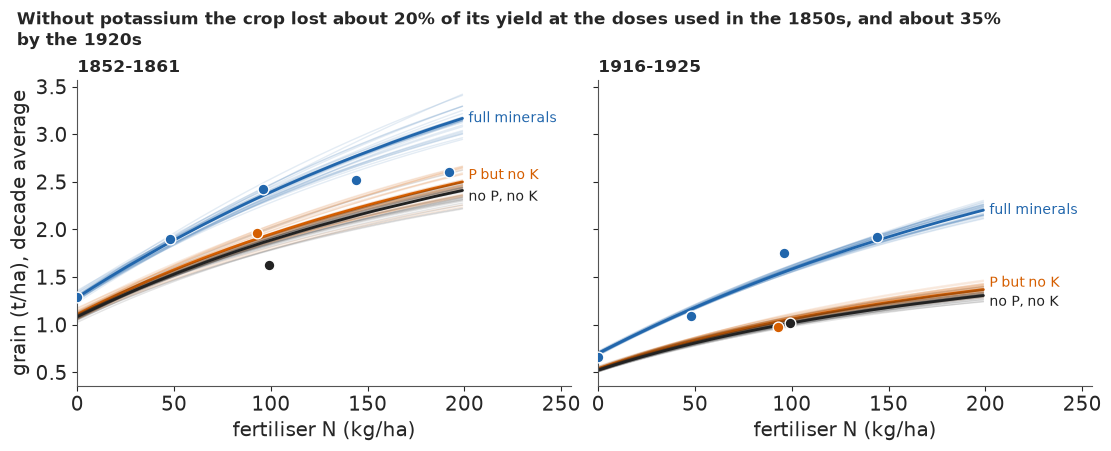

In [13]:
PP = POST["partial Liebig"]


def soil_n(P, year):
    return P["ns_inf"] + P["ns_gap"] * np.exp(-(year - 1852) / P["tau_s"])


def liebig_curves(P, years, NN):
    """Yield (t/ha) against fertiliser N for full minerals, no K, no P/K, averaged over `years`."""
    A = np.exp(P["a0"][:, None] + P["eta"][:, years - 1852]).mean(1)
    s = (years.mean() - 1852) / 73
    f = 1 - np.exp(-P["c"][:, None] * (NN[None, :] / 100 + soil_n(P, years.mean())[:, None]))
    lK = P["lamK"][:, 0] + P["lamK"][:, 1] * s
    lP = P["lamP"][:, 0] + P["lamP"][:, 1] * s
    out = {}
    for nm, pen in (("full minerals", 0 * lK), ("P but no K", lK), ("no P, no K", lK + lP)):
        out[nm] = A[:, None] * f * np.exp(-pen[:, None] * f ** P["gam"][:, None])
    return out


NN = np.arange(0, 200.0)
STRIP_PTS = {"full minerals": [("P05", 0), ("P06", 48), ("P07", 96), ("P08", 144), ("P16", 192)],
             "P but no K": [("P11", 96)], "no P, no K": [("P10", 96)]}
COLS = {"full minerals": HI, "P but no K": LO, "no P, no K": INK}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
pick = rng.choice(PP["c"].size, 30, replace=False)
LOSS_K = {}
for ax, (y0, y1) in zip(axes, ((1852, 1861), (1916, 1925))):
    yrs = np.arange(y0, y1 + 1)
    cur = liebig_curves(PP, yrs, NN)
    for nm, Y in cur.items():
        for i in pick:
            ax.plot(NN, Y[i], color=COLS[nm], alpha=0.12, lw=1)
        ax.plot(NN, np.median(Y, 0), color=COLS[nm], lw=2)
        lab_y = np.median(Y, 0)[-1] + {"P but no K": 0.07, "no P, no K": -0.07}.get(nm, 0)
        ax.text(200, lab_y, " " + nm, color=COLS[nm], va="center", fontsize=10)
        for plot, n in STRIP_PTS[nm]:
            obs = D[(D["plot"] == plot) & D.year.between(y0, y1) & (D.n_kg == n)].grain
            if len(obs):  # strips 10 and 11 share a dose: nudge them apart so neither hides
                ax.scatter(n + {"P10": 3, "P11": -3}.get(plot, 0), obs.mean(), color=COLS[nm],
                           edgecolor="white", s=60, zorder=5)
    ax.set_xlim(0, 255)
    ax.set_xlabel("fertiliser N (kg/ha)")
    ax.set_title(f"{y0}-{y1}", loc="left", fontsize=12)
    at = [96, 144, 191]  # NN runs 0-199 kg
    loss = 1 - cur["P but no K"][:, at] / cur["full minerals"][:, at]
    LOSS_K[y0] = np.median(loss, 0)
    print(f"{y0}-{y1}: yield lost without K at 96 / 144 / 191 kg N: "
          + " / ".join(f"{v:.0%}" for v in LOSS_K[y0]))
axes[0].set_ylabel("grain (t/ha), decade average")
fig.suptitle(wrap(f"Without potassium the crop lost about {LOSS_K[1852].mean():.0%} of its yield "
                  f"at the doses used in the 1850s, and about {LOSS_K[1916].mean():.0%} by the "
                  "1920s", 100), x=0.01, ha="left", fontsize=12.5)
for y in (1852, 1925):
    s = (y - 1852) / 73
    lk = PP["lamK"][:, 0] + PP["lamK"][:, 1] * s
    print(f"{y}: K penalty lambda_K {np.median(lk):.2f}, yield multiplier without K for a crop at "
          f"its ceiling (f = 1, beyond any dose used) {np.median(np.exp(-lk)):.2f}")
print(f"gamma {np.median(PP['gam']):.2f}; Na softens the K penalty by "
      f"{np.median(PP['w_na']):.0%}, Mg by {np.median(PP['w_mg']):.0%}")

At the doses actually used, 96-192 kg N, a crop without potassium gave about a fifth less than one
with full minerals in the 1850s, and about a third less by the 1920s, as the soil's own potassium
ran out. The printed multipliers (0.76 and 0.53) are larger losses because they describe a crop
at its ceiling, which no strip reached. Leaving out phosphorus as well costs little more:
Broadbalk's soil held phosphorus far longer. The gap widens with nitrogen, the partial-Liebig
shape. In this model sodium and magnesium each cancel about 70% of the potassium penalty, which is
why strips 12 and 14 (with Na or Mg but no K) yield far more than strip 11; these are their own
heavier dressings of sodium and magnesium sulphate, not the small amounts in the full mixture.
The points are raw decade means of single strips, and some sit well off their curves (strip 10
in the 1850s, strip 7 in the 1920s, and the two highest doses in the 1850s, the overshoot of
part C): partly each strip's own soil, the subject of the next part.

## E · Strips, manure and memory

### Fisher's point

Every treatment on Broadbalk is applied to one strip. If strip 7 happens to have better soil than
strip 6, the "second bag" looks better than it is, and no amount of years can tell that from the
shape of the curve: each year repeats the same comparison of the same two strips. This is why
Fisher (1926) insisted on replicated, randomised plots. We cannot replicate the past, but we can
say what we do not know: give each strip its own effect $u_p$ on the log scale, shrunk towards
zero by a common sd $s_u \sim \text{HalfNormal}(0.1)$, and constrained to sum to zero over the 15
strips (`pm.ZeroSumNormal`) so that it cannot absorb the overall level. The manure strip 2b gets
none: its treatment is unique, and its manure term already is its effect.

The strip effects are identified only because some treatments recur on several strips: N2 with
full minerals is on strips 7, 15 (in autumn), 16 (from 1884, as nitrate), 17 and 18 (in
alternate years). Those strips pin down how much of a difference between treatments is soil.

### What the table of averages cannot see

A model can match every average in part C's table while getting the spread wrong, and part F's
question depends on the spread: how much the third bag's return varies from year to year.
Strips 5-8 measure that directly, so we replay their yearly increments through the naive model
and compare the interquartile range (IQR) and sd with the real ones. We also ask whether the
residuals of different strips move together within a year, which independent noise says not.

In [14]:
def spread_check(lrep, label):
    """Year-to-year spread of each bag's raw increment (strips 5-8): observed against replayed."""
    rows = []
    for j, (a, b) in enumerate((("P06", "P05"), ("P07", "P06"), ("P08", "P07"))):
        ia, ib = (np.flatnonzero((D["plot"] == p).to_numpy()) for p in (a, b))
        obs = 1000 * (W[a] - W[b]).to_numpy()
        rep = 1000 * (np.exp(lrep[:, ia]) - np.exp(lrep[:, ib]))
        riqr = np.subtract(*np.quantile(rep, [0.75, 0.25], axis=1))
        rows.append({"bag": j + 1, "observed IQR": np.subtract(*np.quantile(obs, [0.75, 0.25])),
                     "replayed IQR": np.median(riqr), "89% low": np.quantile(riqr, 0.055),
                     "89% high": np.quantile(riqr, 0.945), "observed sd": obs.std(ddof=1),
                     "replayed sd": np.median(rep.std(axis=1, ddof=1))})
    print(f"{label}: interquartile range and sd of the yearly increment (kg/ha), strips 5-8")
    print(pd.DataFrame(rows).set_index("bag").round(0).to_string())
    res = pd.DataFrame({"plot": D["plot"], "year": D.year, "r": LOGY - np.median(lrep, 0)})
    cor = res.pivot_table(index="year", columns="plot", values="r")[["P05", "P06", "P07", "P08",
                                                                     "P16"]].corr()
    print("correlation of the residuals within a year:")
    print(cor.round(2).to_string())


spread_check(LREP_NAIVE, "naive model")
del LREP_NAIVE

naive model: interquartile range and sd of the yearly increment (kg/ha), strips 5-8
     observed IQR  replayed IQR  89% low  89% high  observed sd  replayed sd
bag                                                                         
1           333.0         429.0    338.0     535.0        257.0        410.0
2           287.0         536.0    420.0     671.0        204.0        535.0
3           315.0         629.0    487.0     783.0        245.0        644.0
correlation of the residuals within a year:
plot   P05   P06   P07   P08   P16
plot                              
P05   1.00  0.15 -0.34 -0.29 -0.38
P06   0.15  1.00  0.36 -0.13 -0.44
P07  -0.34  0.36  1.00  0.50  0.31
P08  -0.29 -0.13  0.50  1.00  0.62
P16  -0.38 -0.44  0.31  0.62  1.00


The naive model's increments are about twice as spread out as the real ones: for the third bag
an IQR of about 630 kg against 315, far outside the replay's own 89% range (about 490-790). Two
things are missing. The residuals are correlated within a year, by about +0.5 to +0.6 among the
well-fed strips 7, 8 and 16 and negatively against strips 5 and 6: the weather does not only
raise or lower the whole field, it changes what nitrogen does. A wet summer that lodges a heavy
crop hurts strip 8 more than strip 5. And a single noise scale is set by the erratic strips (10,
11 and 15 among them), which makes it far too wide for the steady full-mineral ones.

The main model adds a term for each. The **year-by-dose term**, with $N$ the fertiliser in units
of 100 kg,

$$ \log \mu_{pt} \;\mathrel{+}=\; \zeta_{1t}\,(N_{pt} - 1) + \zeta_{2t}\,igl((N_{pt} - 1)^2 -
   	frac12igr), \qquad \zeta_{kt} = s_k z_{kt}, $$

lets each year tilt and bend the response around the N2 dose, with $z_{k\cdot}$ summing to zero
over the years (so the average curve stays the curve) and $s_k \sim 	ext{HalfNormal}(0.2)$. The
**noise scale of each strip** is $\sigma_p = \sigma\, e^{s_\sigma z_p}$, $s_\sigma \sim
	ext{HalfNormal}(0.5)$, shrunk towards the common one. With the strip effects, that is the main
model.

In [15]:
m_main = build(liebig="partial", strips=True, noise=True)
id_main = fit(m_main, "main", tune=800)
for v in ("s_u", "u", "s_zeta", "sigma", "s_sig", "sig_p", "nu"):
    print(az.summary(id_main, var_names=[v], round_to=3)[["mean", "sd", "eti89_lb", "eti89_ub",
                                                          "r_hat"]].to_string(header=v == "s_u"))
print(az.compare(LOOS, round_to=1)[["elpd", "elpd_diff", "dse", "p"]].to_string())

[main] 97 s, tuning 800, divergences 0, worst r_hat 1.010 (eta), min bulk ESS 330 (a0), elpd_loo 626.2 (se 36.0), Pareto k > 0.7: 0
      mean     sd  eti89_lb  eti89_ub  r_hat
s_u  0.075  0.018     0.051     0.107  1.001
u[P03]  0.038  0.045 -0.031  0.113  1.001
u[P05] -0.000  0.040 -0.059  0.071  1.002
u[P06] -0.011  0.018 -0.040  0.018  1.002
u[P07]  0.048  0.017  0.019  0.075  1.000
u[P08] -0.005  0.022 -0.041  0.028  1.001
u[P09]  0.067  0.033  0.015  0.119  1.000
u[P10] -0.129  0.050 -0.208 -0.049  1.002
u[P11] -0.111  0.037 -0.169 -0.049  1.001
u[P12]  0.059  0.030  0.013  0.108  0.999
u[P13]  0.062  0.041  0.010  0.136  1.001
u[P14]  0.077  0.029  0.034  0.126  1.001
u[P15] -0.014  0.038 -0.075  0.046  1.002
u[P16] -0.046  0.037 -0.106  0.012  1.002
u[P17] -0.029  0.020 -0.061  0.002  1.001
u[P18] -0.006  0.022 -0.041  0.029  1.001
s_zeta[0]  0.105  0.016  0.082  0.131  1.003
s_zeta[1]  0.165  0.021  0.133  0.201  1.002
sigma  0.087  0.012  0.069  0.106  1.0
s_sig  0.469  0.097

nu  3.113  0.394  2.558  3.793  1.0
                 elpd  elpd_diff   dse      p
main            626.2        0.0   0.0  247.1
partial Liebig  366.8     -259.4  23.8  104.9
naive           350.7     -275.5  24.7  102.3
Liebig minimum  221.9     -404.3  29.8  102.1


The sampler is clean (no divergences, r_hat at most 1.01, bulk ESS at least about 330), and the
main model beats the partial Liebig fit by about 260 points of elpd (standard error about 24). The
year-by-dose terms have sds of about 0.10 and 0.17 on the log scale, so the year moves the yield
at the fourth dose relative to N2 by about 17% (one sd), on top of what the ceiling does. The
noise scales run from about 0.04 on strip 7 to 0.16-0.18 on strips 10, 11 and 15, a fourfold
range.

The strip effects have an sd of about 0.08: strips differ by about 8% for reasons the treatments
do not explain. Strip 7, the N2 strip that made the second bag look better than the first, sits
about 5% above average; strip 16 about 5% below. Strips 10 and 11 come out 11-13% low, and here a
warning is due: they are also the strips without potassium, so part of their strip effect is
penalty the time trend did not capture. The same trade happens at the other end: with strip
effects, the potassium penalty in 1852 shrinks to about 0.10 (0.28 without them), and sodium and
magnesium cancel only about a third and a fifth of it instead of 70%, because strips 12 and 14 now
explain part of their good yields by their own soil (+6% and +8%). Which split is right, an
unreplicated design cannot say. The strip effects make the model honest about the design, not
about each strip's soil.

In [16]:
TAB_MAIN, PRED_MAIN, LREP_MAIN = by_treatment(m_main, id_main, "main")
print(TAB_MAIN.to_string())
spread_check(LREP_MAIN, "main model")
print(az.summary(id_main, var_names=["a0", "s_eta", "phi", "c", "ns_inf", "ns_gap", "tau_s", "gam",
                                     "lamK", "w_na", "w_mg", "e_nit", "e_aut", "rho", "nman",
                                     "tau_m"],
                 round_to=3)[["mean", "sd", "eti89_lb", "eti89_ub", "ess_bulk", "r_hat"]]
      .to_string())

main: overall 89% coverage 0.93; obs and pred are geometric means
                                           strip   n   obs  pred  cover89
note                                                                     
nil                                          P03  74  0.79  0.80     0.92
PKNaMg                                       P05  74  0.92  0.93     0.96
PKNaMg year (N2 last year)               P17,P18  74  0.94  0.96     0.86
N2                                           P10  74  1.27  1.34     0.91
N2 P                                         P11  74  1.41  1.48     0.86
N1 PKNaMg                                    P06  74  1.48  1.51     0.92
N1* PKNaMg                                   P09  32  1.70  1.69     0.97
N2 PKNaMg, N timing differs from plot 7      P15  53  1.76  1.82     0.92
N2 P Mg                                      P14  74  1.83  1.86     0.89
N2 P Na                                      P12  74  1.85  1.87     0.89
N2 year (minerals last year)             P17,P

           mean      sd  eti89_lb  eti89_ub  ess_bulk  r_hat
a0        1.580   0.157     1.343     1.847   330.050  1.008
s_eta     0.294   0.031     0.251     0.347   877.551  1.003
phi       0.313   0.111     0.141     0.496   676.560  1.006
c         0.339   0.072     0.230     0.460   340.554  1.009
ns_inf    0.457   0.087     0.303     0.586   597.011  1.006
ns_gap    0.450   0.133     0.247     0.673   554.271  1.005
tau_s    34.967  14.948    16.587    62.607   880.030  1.005
gam       0.535   0.154     0.300     0.784  1475.969  1.003
lamK[0]   0.102   0.067     0.013     0.221  1533.143  1.003
lamK[1]   0.455   0.105     0.312     0.637   715.344  1.004
w_na      0.320   0.135     0.110     0.544  6492.664  1.000
w_mg      0.204   0.108     0.053     0.396  6805.995  1.002
e_nit     1.376   0.115     1.200     1.560  2056.229  1.001
e_aut     0.903   0.076     0.786     1.025  1868.556  1.001
rho       0.039   0.024     0.005     0.081  1647.165  1.002
nman      4.649   1.119 

Most treatments' geometric means are now within a few hundredths of a tonne, the manure strip
included. The misses that remain are strips 10, 11 and 15, predicted 0.06-0.07 t high (strip 10
at about 1.34 against 1.27, from the naive 1.48); the fourth dose, about 2.72 against 2.70, is
now matched. Coverage is between about 0.86 and 0.99 for every treatment.

The spread check now passes: the third bag's replayed IQR is about 340 kg against 315 observed
(89% range 265-430), the first bag's matches, and the second bag's observed 287 sits just inside
its range. One thing remains: residuals of the neighbouring well-fed strips 7, 8 and 16 still
correlate by about +0.4 within a year. Part of one plot's luck in a year is its neighbours' too.

The soil supplied the equivalent of about 90 kg N/ha in 1852 (a settled $n_\infty$ of about 46 kg
plus a start-up excess of about 45 kg) and lost the excess slowly, with a time constant of about
35 years (17-63). Carry-over of last year's dose is about 4%: what the crop does not take in its
year is gone, to the drains and the air. Sodium nitrate counts as about 1.4 times its nitrogen in
ammonium, but treat that with care: only strips 9 and 16 ever got it, each with its own strip
effect, so the efficiency and those two strips' soils trade off (part F prints how much). Autumn
ammonium is about 0.9 times as good as split, though the data cannot separate autumn from the
1852-77 period in which it was used.

### The weather of each year

The year potentials $A_t / e^{a_0} = e^{\eta_t}$ are the model's account of each year's weather,
with the fertiliser taken out. As a row of stripes (after the climate stripes of Ed Hawkins),
brown is a year that sank the whole field and green a year that lifted it, read off the key below
the stripes; a hatched stripe is a year we cannot tell from an average one at 89%.

worst years: {1912: 0.39, 1924: 0.51, 1923: 0.54, 1879: 0.55, 1853: 0.61}
best years: {1894: 1.6, 1863: 1.6, 1905: 1.59, 1906: 1.55, 1890: 1.44}
hatched: 28 of 74; year sd s_eta 0.29, phi 0.31


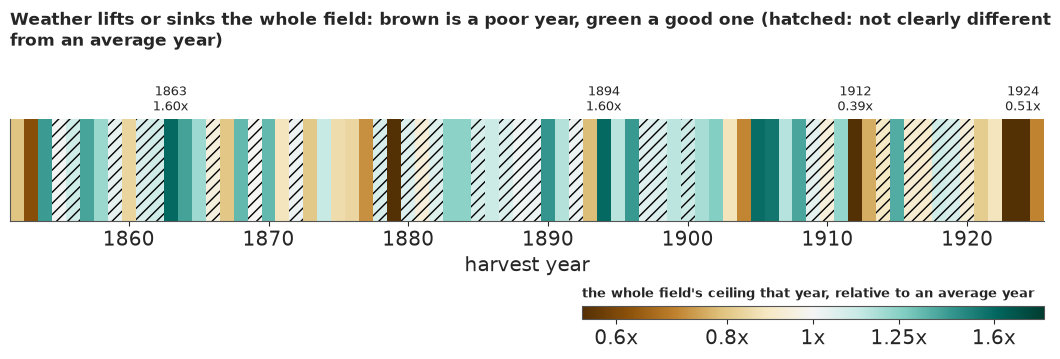

In [17]:
PM = POST["main"]
rel = np.exp(PM["eta"])
med, lo, hi = np.median(rel, 0), *np.quantile(rel, [0.055, 0.945], 0)
fig, ax = plt.subplots(figsize=(11, 3.4), layout="none")
fig.subplots_adjust(left=0.03, right=0.97, top=0.66, bottom=0.36)
cm = plt.get_cmap("BrBG")
cax = fig.add_axes([0.55, 0.07, 0.42, 0.04])  # the key: colour = multiplier, log scale
cbar = fig.colorbar(plt.cm.ScalarMappable(LogNorm(np.exp(-0.6), np.exp(0.6)), cm), cax=cax,
                    orientation="horizontal")
cbar.set_ticks([0.6, 0.8, 1.0, 1.25, 1.6], labels=["0.6x", "0.8x", "1x", "1.25x", "1.6x"])
cbar.minorticks_off()
cax.set_title("the whole field's ceiling that year, relative to an average year", fontsize=9.5,
              loc="left")
for i, y in enumerate(YEARS):
    v = np.clip((np.log(med[i]) / 0.6 + 1) / 2, 0, 1)
    ax.add_patch(plt.Rectangle((y - 0.5, 0), 1, 1, fc=cm(v), ec="none",
                               hatch="///" if lo[i] < 1 < hi[i] else None))
ax.set_xlim(1851.5, 1925.5)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xlabel("harvest year")
order = np.argsort(med)
for i in (*order[:2], *order[-2:]):
    ax.text(YEARS[i], 1.04, f"{YEARS[i]}\n{med[i]:.2f}x", ha="center", va="bottom", fontsize=9)
fig.suptitle(wrap("Weather lifts or sinks the whole field: brown is a poor year, green a good one "
                  "(hatched: not clearly different from an average year)", 110), x=0.03, y=0.98,
             ha="left", va="top", fontsize=12.5)
print("worst years:", {int(YEARS[i]): round(float(med[i]), 2) for i in order[:5]})
print("best years:", {int(YEARS[i]): round(float(med[i]), 2) for i in order[-5:][::-1]})
print(f"hatched: {int(((lo < 1) & (hi > 1)).sum())} of 74; year sd s_eta "
      f"{np.median(PM['s_eta']):.2f}, phi {np.median(PM['phi']):.2f}")

1912 was the worst year, the whole field at about two fifths of its usual ceiling, followed by
1924, 1923, 1879 (the cold, wet summer that also wrecked British harvests elsewhere) and 1853. The
best, 1894 and 1863, lifted it by about 60%. Most years are clearly good or bad; about a third are
hatched. The year-to-year correlation $\phi$ is small, about 0.3: one bad harvest barely
predicts the next, so for a farmer next year's weather is close to a fresh draw.

## F · Does the last bag pay?

### Two questions with the same words

For a modern farmer the relevant soil is a settled one ($N_s = n_\infty$), the fertiliser split
ammonium with full minerals, and the strip an average one ($u = 0$). With $F_j = f(0.48j +
n_\infty)$ for $j$ bags, there are two ways to ask what bag $j$ adds.

**In an average year** (inference): $\Delta_j = \bar A\,(F_j - F_{j-1})$ with $\bar A = E[A_t] =
e^{a_0 + s_\eta^2/2}$ and the year-by-dose term at zero, its average. (Averaging over that term
too would change the returns by well under 1% inside the tested doses.) Its posterior says how
sure we are about the average return, and shrinks as data accumulate.

**In one new year on one small plot** (prediction): draw a fresh year, $\eta \sim N(0, s_\eta)$
and $\zeta_k \sim N(0, s_k)$, and Student-t noise $\epsilon_{j}, \epsilon_{j-1}$ for two
neighbouring plots the size of a Broadbalk strip (a fraction of a hectare), one with $j-1$ bags
and one with $j$, at the noise scale of strips 7 and 8, which carry the third bag. Then
$y_j - y_{j-1} = e^{a_0+\eta}\,(F_j\, e^{\zeta \cdot h_j + \epsilon_j} - F_{j-1}\, e^{\zeta \cdot
h_{j-1} + \epsilon_{j-1}})$, with $h_j$ the two year-by-dose shapes at $j$ bags. This is the kind
of quantity the raw increments of part A measure, but for two average plots in a fresh year, so
a like-for-like check needs the replay below. It does not shrink with more data. Dropping the
$\epsilon$ terms leaves the weather alone; dropping $\zeta$ too leaves only the ceiling.

The bag pays if it adds more than $48R$ kg. Every number below is per hectare.

In [18]:
BAGS = np.array([0, 48, 96, 144, 192]) / 100
NGRID = np.arange(0, 401.0)
RATIOS = (4, 5, 6, 8, 10, 12)


def fcurve(kind, par, x):
    if kind == "qp":
        return 1 - (1 - np.minimum(par * x, 1.0)) ** 2
    return 1 - np.exp(-par * x)


I7P, I8P = list(PLOTS).index("P07"), list(PLOTS).index("P08")


def decide(P, kind="mit", seed=RANDOM_SEED):
    r = np.random.default_rng(seed)
    par = P["b"] if kind == "qp" else P["c"]
    n = par.size
    EA = np.exp(P["a0"] + P["s_eta"] ** 2 / 2)
    F = fcurve(kind, par[:, None], BAGS[None, :] + P["ns_inf"][:, None])
    eta = r.normal(0, P["s_eta"])
    if "s_zeta" in P:  # a fresh year-by-dose effect; plot noise of a strip fed like 7 and 8
        shape = np.exp(np.sum(r.normal(0, P["s_zeta"])[:, None, :] * hx(BAGS)[None], axis=-1))
        sig = np.sqrt(P["sig_p"][:, I7P] * P["sig_p"][:, I8P])
    else:
        shape, sig = np.ones((n, 5)), P["sigma"]
    eps = stats.t.rvs(df=P["nu"][:, None], scale=sig[:, None], size=(n, 5), random_state=r)
    Ay = np.exp(P["a0"] + eta)[:, None]
    out = dict(avg=np.diff(EA[:, None] * F, axis=1) * 1000,
               one=np.diff(Ay * F * shape * np.exp(eps), axis=1) * 1000,
               weather=np.diff(Ay * F * shape, axis=1) * 1000,
               ceiling=np.diff(Ay * F, axis=1) * 1000)
    for nm, zq in (("poor", -1.2816), ("typical", 0.0), ("good", 1.2816)):
        out[nm] = np.diff(np.exp(P["a0"] + zq * P["s_eta"])[:, None] * F, axis=1) * 1000
    Fg = fcurve(kind, par[:, None], NGRID[None, :] / 100 + P["ns_inf"][:, None])
    mp = np.gradient(EA[:, None] * Fg * 1000, NGRID, axis=1)  # kg grain per kg N
    out["eonr"] = {}
    for R in RATIOS:
        below = mp < R
        out["eonr"][R] = np.where(below.any(1), NGRID[np.argmax(below, 1)], 400.0)
    return out


def bag_table(dec, R=5):
    be = BAG * R
    rows = []
    for j in range(4):
        a = dec["avg"][:, j]
        rows.append({"bag": j + 1, "avg-year mean": a.mean(), "89% low": np.quantile(a, 0.055),
                     "89% high": np.quantile(a, 0.945), "P(pays), avg year": np.mean(a > be),
                     "P(pays), one plot": np.mean(dec["one"][:, j] > be),
                     "P(pays), weather": np.mean(dec["weather"][:, j] > be),
                     "P(pays), ceiling": np.mean(dec["ceiling"][:, j] > be)})
    return pd.DataFrame(rows).set_index("bag")


DEC = {"main": decide(PM)}
print(f"break-even at R = 5: {BAG * 5} kg of grain per bag")
print(bag_table(DEC["main"]).round(2).to_string())
P_AV = float(np.mean(DEC["main"]["avg"][:, 2] > 240))
P_ONE = float(np.mean(DEC["main"]["one"][:, 2] > 240))
P_WEA = float(np.mean(DEC["main"]["weather"][:, 2] > 240))
P_CEIL = float(np.mean(DEC["main"]["ceiling"][:, 2] > 240))
print(f"bag 3: average year {DEC['main']['avg'][:, 2].mean():.0f} kg; pays on average "
      f"{pub.fmt_pct(P_AV)} ({pub.calibrated_word(P_AV)}); one plot in one new year {P_ONE:.0%}; "
      f"weather alone {P_WEA:.0%} (ceiling only {P_CEIL:.0%}); raw strips 8 - 7: {P_RAW3:.0%}")
for nm in ("one", "weather"):
    qs = np.quantile(DEC["main"][nm][:, 2], [0.05, 0.25, 0.5, 0.75, 0.95])
    print(f"bag 3, {nm}: 5/25/50/75/95% " + " / ".join(f"{v:.0f}" for v in qs))
# like for like: the model's own replicate of strips 8 and 7 in the observed years, with their
# strip effects, weather, timing and soil, from the posterior predictive draws of part E
I7, I8 = (np.flatnonzero((D["plot"] == p).to_numpy()) for p in ("P07", "P08"))
assert (YR[I7] == YR[I8]).all()
REP3 = np.exp(LREP_MAIN[:, I8]) - np.exp(LREP_MAIN[:, I7])  # draws x years, t/ha
SHARE = np.mean(REP3 > 0.240, axis=1)
print(f"replicated strip 8 - strip 7: bag 3 clears 240 kg in {np.median(SHARE):.0%} of years "
      f"(89% {np.quantile(SHARE, 0.055):.0%}-{np.quantile(SHARE, 0.945):.0%}), observed "
      f"{P_RAW3:.0%}; median increment {1000 * np.median(np.median(REP3, 1)):.0f} kg, observed "
      f"{1000 * INC['bag 3'].median():.0f}")

break-even at R = 5: 240 kg of grain per bag
     avg-year mean  89% low  89% high  P(pays), avg year  P(pays), one plot  P(pays), weather  P(pays), ceiling
bag                                                                                                            
1           639.99   569.59    719.95                1.0               0.98              0.99              1.00
2           543.73   485.97    605.91                1.0               0.90              0.97              1.00
3           462.50   406.38    522.76                1.0               0.79              0.90              0.98
4           393.87   330.80    457.88                1.0               0.63              0.65              0.93
bag 3: average year 463 kg; pays on average >99% (virtually certain); one plot in one new year 79%; weather alone 90% (ceiling only 98%); raw strips 8 - 7: 61%
bag 3, one: 5/25/50/75/95% 45 / 268 / 429 / 605 / 1008
bag 3, weather: 5/25/50/75/95% 202 / 323 / 431 / 565 / 831
replicate

Each bag adds less than the one before, about 640, 540, 460 and 390 kg in an average year, and
the third bag's average return is pinned down to within about ±60 kg: its whole posterior lies
far above the 240 kg break-even, so it is *virtually certain* to pay on average. That precision is
conditional on the model: with N3 on a single strip, strip 8's soil is pinned near average only
by the shape of the curve, and strip 7's (about 5% above average) rests on the strips that share
its treatment. Without those effects the raw increment is about 310 kg, still above break-even.

On one small plot in one new year the same bag pays about 79% of the time. The raw strips gave
61%, but that is not the same quantity: strips 7 and 8 have their own soils, and the record
includes the early years, when the soil's own nitrogen was higher and the third bag added less
(part A). The like-for-like check replays strips 8 and 7 in the observed years: the bag clears
240 kg in about 59% of them (89%: 50-69%), bracketing the observed 61%, and the replayed median
increment, about 300 kg, matches the observed 295.

The last two columns split that risk. With the weather varying (ceiling and year-by-dose term)
but every plot behaving as the curve says, the third bag would pay in about 90% of years; with
only the ceiling varying, in 98%. The year's effect on the *shape* of the response takes about 8
points off, and what happens to one plot in one year (lodging, disease, birds, the error of
weighing a Victorian harvest) about 11 more. A farm's plots share their year and, part E found,
part of their luck, so a farm's chance lies above 79% by an amount this model cannot say.

### Kinds of year

A farmer cannot know the weather when spreading, but can ask what the bag is worth in a poor, a
typical and a good year, here the 10th, 50th and 90th percentiles of the year potential.

In [19]:
for nm in ("poor", "typical", "good"):
    a = DEC["main"][nm]
    print(f"{nm:>8} year: bags 1-4 add " + ", ".join(f"{v:.0f}" for v in a.mean(0))
          + f" kg; bag 3 pays in {np.mean(a[:, 2] > 240):.0%} of draws, bag 4 in "
          f"{np.mean(a[:, 3] > 240):.0%}")

    poor year: bags 1-4 add 421, 358, 304, 259 kg; bag 3 pays in 99% of draws, bag 4 in 75%
 typical year: bags 1-4 add 613, 521, 443, 377 kg; bag 3 pays in 100% of draws, bag 4 in 100%
    good year: bags 1-4 add 893, 759, 646, 550 kg; bag 3 pays in 100% of draws, bag 4 in 100%


Even in a poor year (one year in ten is worse) the third bag adds about 300 kg on average and
pays in almost every posterior draw (99%); in a good year it adds about 650. The fourth bag is
where the kind of year starts to matter: in a poor year it adds about 260 kg and pays in three
draws in four (75%). The typical year's third bag, about 440 kg, sits a little below the average
year's 460: the typical year is the median one, and the few very good years lift the average.
These kinds of year are set by the ceiling alone, with the year-by-dose term at its average.
Part G draws them as columns of dots.

### The economic optimum rate

The EONR is the dose at which one more kg of nitrogen adds exactly $R$ kg of grain, found per
posterior draw on a grid up to 400 kg N/ha. We draw each ratio's posterior as a gradient strip
(darker = more plausible; Correll & Gleicher 2014 found that error bars are read as hard limits)
and mark the most nitrogen ever applied on Broadbalk in this period, 192 kg.

R =  4: EONR median 383 kg N/ha, 89% 291-400, beyond 192 kg in 100%, at the 400 cap 41%
R =  5: EONR median 316 kg N/ha, 89% 242-400, beyond 192 kg in 100%, at the 400 cap 12%
R =  6: EONR median 262 kg N/ha, 89% 200-357, beyond 192 kg in 97%, at the 400 cap 2%
R =  8: EONR median 176 kg N/ha, 89% 133-237, beyond 192 kg in 32%, at the 400 cap 0%
R = 10: EONR median 109 kg N/ha, 89% 76-151, beyond 192 kg in 0%, at the 400 cap 0%
R = 12: EONR median 54 kg N/ha, 89% 20-88, beyond 192 kg in 0%, at the 400 cap 0%


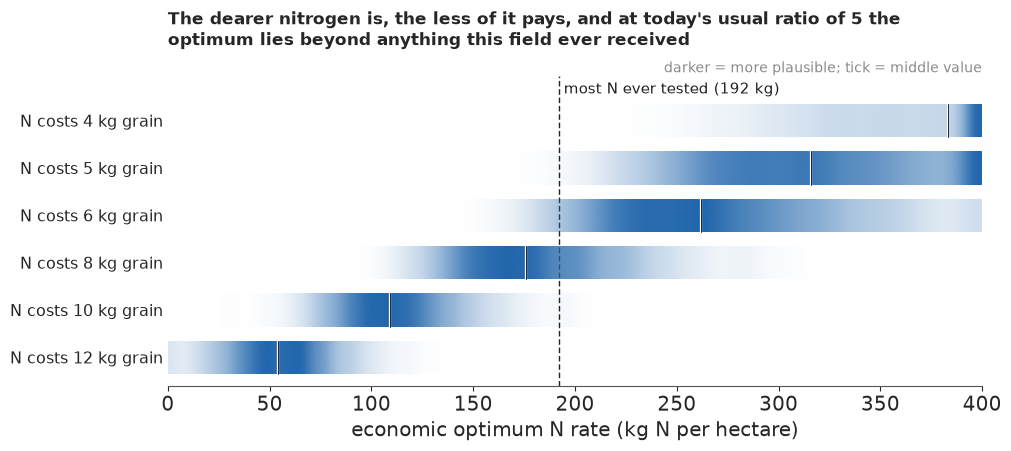

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.4))
pub.gradient_intervals(ax, [DEC["main"]["eonr"][R] for R in RATIOS],
                       [f"N costs {R} kg grain" for R in RATIOS], xlim=(0, 400), ref=192,
                       ref_label="most N ever tested (192 kg)",
                       xlabel="economic optimum N rate (kg N per hectare)")
ax.set_title(wrap("The dearer nitrogen is, the less of it pays, and at today's usual ratio of 5 "
                  "the "
                  "optimum lies beyond anything this field ever received", 85), loc="left",
             fontsize=12.5, pad=22)
for R in RATIOS:
    e = DEC["main"]["eonr"][R]
    print(f"R = {R:>2}: EONR median {np.median(e):.0f} kg N/ha, 89% {np.quantile(e, 0.055):.0f}-"
          f"{np.quantile(e, 0.945):.0f}, beyond 192 kg in {np.mean(e > 192):.0%}, at the 400 cap "
          f"{np.mean(e >= 400):.0%}")

At $R = 5$ the optimum's median is about 315 kg N/ha (89%: 240 to the 400 kg edge of the grid,
which holds 12% of the draws), and in every draw it lies beyond 192 kg, the most nitrogen ever put
on this field before 1926. That number is not a finding about Broadbalk; it is Mitscherlich's
exponential tail, extrapolated. At $R = 8$ (2022 prices) the optimum falls to about 175 kg
(135-235), mostly inside the tested doses, and is much better determined. A question about the
third bag, inside the data, is answerable; a question about the "optimum rate" at cheap nitrogen
is mostly a question about the shape of the curve.

It is also partly a question about the prior. The curvature $c$ lands low in its prior, and the
ceiling $e^{a_0}$, about 4.8 t/ha, lies above the single best strip-year in the record (4.1) and
far above what any dose reached on average (2.7 at most): the data prefer a gentle curve with a
distant ceiling, and the prior pulls the other way. Since the posterior is the prior times the
likelihood, we can swap the prior on $c$ without refitting, by weighting each draw by the ratio of
the new prior to the old one. The weights only reach where the fitted posterior has draws, so
PSIS's Pareto $k$ says whether the reweighting can be trusted (below 0.7). We also double the
prior scale of the strip effects, on which the third bag's precision rests.

In [21]:
def wquant(x, w, q):
    o = np.argsort(x)
    cw = np.cumsum(w[o]) / w.sum()
    return x[o][np.searchsorted(cw, q)]


C_PRIORS = {"LogNormal(0, 0.5), as fitted": (0.0, 0.5),
            "LogNormal(0, 1), twice as wide": (0.0, 1.0),
            "LogNormal(log 0.4, 0.5), gentler": (np.log(0.4), 0.5)}
print(f"posterior: c median {np.median(PM['c']):.2f} (89% {np.quantile(PM['c'], 0.055):.2f}-"
      f"{np.quantile(PM['c'], 0.945):.2f}); prior 89% {np.exp(-1.598 * 0.5):.2f}-"
      f"{np.exp(1.598 * 0.5):.2f}; ceiling exp(a0) {np.median(np.exp(PM['a0'])):.1f} t/ha")
def reweigh(lab, lw):
    """Reweight the posterior draws by a prior ratio; PSIS k says whether that can be trusted."""
    k = (float(xr.DataArray(-lw, dims=["sample"]).azstats.psislw(dim="sample")[1])  # wants -log w
         if np.ptp(lw) > 0 else 0.0)  # the fitted prior itself: all weights equal
    w = np.exp(lw - lw.max())
    a3, e = DEC["main"]["avg"][:, 2], DEC["main"]["eonr"]
    print(f"{lab:>34}: c {wquant(PM['c'], w, 0.5):.2f}, bag 3 average "
          f"{np.sum(w * a3) / w.sum():.0f} kg (89% {wquant(a3, w, 0.055):.0f}-"
          f"{wquant(a3, w, 0.945):.0f}), EONR at R = 5 {wquant(e[5], w, 0.5):.0f} kg, at R = 8 "
          f"{wquant(e[8], w, 0.5):.0f} kg (Pareto k {k:.2f})")


for lab, (mu_, sd_) in C_PRIORS.items():
    reweigh(lab, stats.norm.logpdf(np.log(PM["c"]), mu_, sd_)
            - stats.norm.logpdf(np.log(PM["c"]), 0, 0.5))
reweigh("strip sd s_u ~ HalfNormal(0.2)", stats.halfnorm.logpdf(PM["s_u"], scale=0.2)
        - stats.halfnorm.logpdf(PM["s_u"], scale=0.1))

posterior: c median 0.34 (89% 0.23-0.46); prior 89% 0.45-2.22; ceiling exp(a0) 4.8 t/ha
      LogNormal(0, 0.5), as fitted: c 0.34, bag 3 average 463 kg (89% 406-523), EONR at R = 5 316 kg, at R = 8 176 kg (Pareto k 0.00)
    LogNormal(0, 1), twice as wide: c 0.27, bag 3 average 477 kg (89% 420-535), EONR at R = 5 374 kg, at R = 8 201 kg (Pareto k 0.41)
  LogNormal(log 0.4, 0.5), gentler: c 0.28, bag 3 average 477 kg (89% 420-534), EONR at R = 5 370 kg, at R = 8 199 kg (Pareto k 0.26)
    strip sd s_u ~ HalfNormal(0.2): c 0.34, bag 3 average 462 kg (89% 406-523), EONR at R = 5 316 kg, at R = 8 175 kg (Pareto k 0.34)


The posterior puts $c$ at about 0.34, below its prior's central 89% (0.45-2.2). A prior twice as
wide, or one centred on a gentler curve, lowers $c$ to about 0.27-0.28 and raises the third bag's
average return by only about 15 kg, but moves the optimum at $R = 5$ from about 315 to 370 kg,
and at $R = 8$ from 175 to about 200. Every Pareto $k$ is 0.41 or less, so the reweighting is
usable, though a reweighting only sees where the fitted posterior went, so the true shifts at
cheap nitrogen may be somewhat larger. Doubling the prior scale of the strip effects changes
nothing printed. The answer inside the data barely depends on the prior; the extrapolation
depends on both curve and prior, which brings us back to Cerrato & Blackmer.

### A different curve

The quadratic-plateau curve, the other standard choice in nitrogen trials, gets the same model
otherwise. Its likelihood can have two modes: in a pilot run (not shown) of the model before the
part E terms were added, with nutpie's default start, one chain settled where $\gamma$ is about
12 and the log density about 50 lower (r_hat about 1.5, no divergences). We start every chain
near the good mode found there.

In [22]:
m_qp = build(curve="qp", liebig="partial", strips=True, noise=True)
id_qp = fit(m_qp, "quadratic-plateau", **SIDE,
            initvals={"b": 0.16, "a0": 1.44, "ns_inf": 0.67, "gam": 0.4, "s_u": 0.086})
del id_qp
DEC["quadratic-plateau"] = decide(POST["quadratic-plateau"], "qp")
print(az.compare({k: LOOS[k] for k in ("main", "quadratic-plateau")}, round_to=1)
      [["elpd", "elpd_diff", "dse"]].to_string())
print(bag_table(DEC["quadratic-plateau"]).round(2).to_string())
for R in (5, 8):
    e = DEC["quadratic-plateau"]["eonr"][R]
    print(f"QP, R = {R}: EONR median {np.median(e):.0f}, 89% {np.quantile(e, 0.055):.0f}-"
          f"{np.quantile(e, 0.945):.0f}, beyond 192 kg in {np.mean(e > 192):.0%}")

[quadratic-plateau] 82 s, tuning 1000, divergences 0, worst r_hat 1.057 (a0), min bulk ESS 79 (a0), elpd_loo 628.5 (se 36.1), Pareto k > 0.7: 1
                    elpd  elpd_diff  dse
quadratic-plateau  628.5        0.0  0.0
main               626.2       -2.2  0.9
     avg-year mean  89% low  89% high  P(pays), avg year  P(pays), one plot  P(pays), weather  P(pays), ceiling
bag                                                                                                            
1           608.95   545.75    677.69                1.0               0.97              0.99              1.00
2           558.75   502.38    621.95                1.0               0.93              0.97              1.00
3           508.55   452.59    567.93                1.0               0.84              0.94              0.99
4           458.35   395.78    522.93                1.0               0.68              0.72              0.97
QP, R = 5: EONR median 381, 89% 287-400, beyond 192 kg in 100

LOO barely tells the two curves apart: the quadratic-plateau is ahead by about 2 points with a
standard error of about 1, far too little to choose a curve's shape on (its own fit is a little
rough, r_hat about 1.06 and one Pareto $k$ above 0.7). They agree on the third bag (both put its
average return far above 240 kg, at about 460 and 510, and give a one-plot chance of about 8 in
10, 79% and 84%) and disagree on the optimum rate, where the plateau curve keeps its slope longer:
at $R = 5$ it puts the optimum at about 380 kg instead of 315, and at $R = 8$ near 240 kg, beyond
the tested doses, instead of 175. With predictions this similar, stacking or pseudo-BMA weights
are unstable and say nothing about the curve's shape beyond the data, so we show both and draw the
conclusion that survives both: the third bag, yes; a precise optimum at cheap nitrogen, no.

### Failure: the sharp plateau

The third standard curve, the linear-plateau, has a corner. NUTS needs gradients, so `build`
smooths it, $-\log(e^{-kbx} + e^{-k})/k$; with $k = 12$ the corner is round and sampling is fine,
with $k = 30$ it is nearly sharp. We fit the sharp version once, without strip effects, with the
same settings as everything else.

In [23]:
m_lp = build(curve="lp", liebig="partial", kink=30.0)
id_lp = fit(m_lp, "sharp linear-plateau", **SIDE)
lp_chain = id_lp.posterior["b"].mean("draw").values
lp_logp = id_lp.sample_stats["logp"].mean("draw").values
print("per-chain mean of b:", lp_chain.round(3), "| per-chain mean log density:", lp_logp.round(0))
del id_lp

[sharp linear-plateau] 31 s, tuning 1000, divergences 0, worst r_hat 1.640 (a0), min bulk ESS 7 (a0), elpd_loo 287.6 (se 33.6), Pareto k > 0.7: 0
per-chain mean of b: [0.201 0.195 0.205 0.564] | per-chain mean log density: [264. 264. 264. 195.]


Zero divergences, and r_hat of about 1.64 with an ESS of 7: the chains disagree. One chain sits
in a mode where the plateau starts early ($b$ about 0.57, so the crop is "full" at about 180 kg of
available nitrogen, roughly 100 kg of fertiliser on top of the soil's own supply, between the
second and third doses) with a mean log density about 70 lower; the other three put the corner
beyond any dose tried. The corner makes the likelihood nearly flat in the directions that move
it, so a chain that starts on the wrong side stays there for the whole run; whether one does
depends on its random start. The log-density gap of about 70 settles what the chains cannot: the
early-plateau mode carries a negligible share of the posterior, so "the field was saturated at
N3" is not what the data say. A smoother curve avoids the trap.

### How much does the answer depend on the model?

In [24]:
DEC["partial Liebig, no strips"] = decide(POST["partial Liebig"])
DEC["naive"] = decide(POST["naive"])
rows = []
for k, dec in DEC.items():
    a3, a4, e5, e8 = dec["avg"][:, 2], dec["avg"][:, 3], dec["eonr"][5], dec["eonr"][8]
    fit_name = {"partial Liebig, no strips": "partial Liebig"}.get(k, k)
    rows.append({"model": k, "elpd": LOOS[fit_name].elpd,
                 "bag 3 avg (kg)": f"{a3.mean():.0f} ({np.quantile(a3, .055):.0f}-"
                                   f"{np.quantile(a3, .945):.0f})",
                 "P(pays) avg": pub.fmt_pct(np.mean(a3 > 240)),
                 "P(pays) one year": pub.fmt_pct(np.mean(dec["one"][:, 2] > 240)),
                 "bag 4 avg (kg)": f"{a4.mean():.0f}",
                 "EONR R=5": f"{np.median(e5):.0f} ({np.mean(e5 > 192):.0%} > 192)",
                 "EONR R=8": f"{np.median(e8):.0f}"})
SENS = pd.DataFrame(rows).set_index("model")
print(SENS.round(1).to_string())

                            elpd bag 3 avg (kg) P(pays) avg P(pays) one year bag 4 avg (kg)          EONR R=5 EONR R=8
model                                                                                                                 
main                       626.2  463 (406-523)        >99%              79%            394  316 (100% > 192)      176
quadratic-plateau          628.5  509 (453-568)        >99%              84%            458  381 (100% > 192)      239
partial Liebig, no strips  366.8  434 (398-478)        >99%              63%            368  288 (100% > 192)      155
naive                      350.7  394 (356-433)        >99%              60%            319   234 (98% > 192)      126


Across four models, two curves and with or without the part E terms, the third bag's
average return runs from about 390 to 510 kg and pays with probability above 99% in every one: the
robust answer. The one-plot chance is not robust: about 60-63% with one pooled noise scale, about
80% with the part E terms. The pooled noise was about twice too wide for strips 7 and 8, and a
wider spread pulls any chance towards 50%, so the lower figures are the ones to distrust. The
optimum rate at $R = 5$ moves by about 150 kg between models (about 235 to 380) and is beyond the
tested doses in almost all of every posterior; at $R = 8$ three models put it at 125-175 kg,
inside the data, and the quadratic-plateau at about 240.

### The fourth bag: a contradiction the design cannot settle

Every model above says the fourth bag adds 320-460 kg in an average year, comfortably more than
the 240 kg it costs. The only direct test disagrees: strip 16 against strip 8 in 1852-64 gave
about 50 kg.

In [25]:
u16 = PM["u"][:, list(STRIPS).index("P16")]
u08 = PM["u"][:, list(STRIPS).index("P08")]
J16, J08 = (np.flatnonzero(((D["plot"] == p) & D.year.between(1852, 1864)).to_numpy())
            for p in ("P16", "P08"))
assert (YR[J16] == YR[J08]).all()
lr_obs = np.log(W.P16 / W.P08).loc[1852:1864]  # 13 yearly log ratios, well defined to average
rep4 = (LREP_MAIN[:, J16] - LREP_MAIN[:, J08]).mean(1)  # the same statistic, replayed
avg4 = rep4 - (u16 - u08)  # the same years for two average strips
pc = lambda v: f"{100 * np.expm1(v):+.1f}%"
print(f"strip 16 over strip 8, 1852-64, mean of the 13 yearly log ratios: observed "
      f"{pc(lr_obs.mean())} (standard error {100 * lr_obs.std() / np.sqrt(13):.1f} points); "
      f"replayed by the main model {pc(np.median(rep4))} (89% {pc(np.quantile(rep4, .055))} to "
      f"{pc(np.quantile(rep4, .945))}); for two average strips {pc(np.median(avg4))}")
print(f"strip 16's effect u: median {np.median(u16):+.2f} (89% {np.quantile(u16, .055):+.2f} to "
      f"{np.quantile(u16, .945):+.2f}); P(u16 < 0) = {np.mean(u16 < 0):.2f}")
u09 = PM["u"][:, list(STRIPS).index("P09")]
r09, r16 = np.corrcoef(PM["e_nit"], u09)[0, 1], np.corrcoef(PM["e_nit"], u16)[0, 1]
print(f"nitrate efficiency e_nit {np.median(PM['e_nit']):.2f}; posterior correlation with u09 "
      f"{r09:+.2f}, with u16 {r16:+.2f}")
print(f"raw nitrate gains: strip 9 (N1 nitrate) - strip 6 (N1 ammonium), 1894-1925: "
      f"{1000 * (W.P09 - W.P06).loc[1894:].mean():.0f} kg; strip 16 (N2 nitrate) - strip 7 "
      f"(N2 ammonium), 1884-1925: {1000 * (W.P16 - W.P07).loc[1884:].mean():.0f} kg")
del LREP_MAIN, REP3

strip 16 over strip 8, 1852-64, mean of the 13 yearly log ratios: observed +2.1% (standard error 1.3 points); replayed by the main model +0.3% (89% -8.3% to +10.2%); for two average strips +4.5%
strip 16's effect u: median -0.05 (89% -0.11 to +0.01); P(u16 < 0) = 0.90
nitrate efficiency e_nit 1.37; posterior correlation with u09 -0.80, with u16 -0.75
raw nitrate gains: strip 9 (N1 nitrate) - strip 6 (N1 ammonium), 1894-1925: 394 kg; strip 16 (N2 nitrate) - strip 7 (N2 ammonium), 1884-1925: 113 kg


Taken as the mean of the yearly log ratios (a statistic with a well-defined mean, unlike the
difference of two heavy-tailed yields), strip 16 gained about 2.1% over strip 8 (standard error
1.3 points). The model's replay gives about +0.3%, and +4.5% for two average strips in the same
years: far below the average-year fourth bag. Those years had richer soil, and their own
year-by-dose terms, which strip 16 itself helps to fit, bend the curve down at the top dose; the
model now blames the years more than strip 16's soil (about 5% below average, $P(u_{16} < 0)
\approx 0.9$). The replay's range (89%: -8% to +10%) is much wider than this pair's real yearly
spread (sd about 5%): strips 8 and 16, side by side and similarly fed, share much of their yearly
luck, which independent plot noise cannot carry. So this check is weak, not reassuring.

Is strip 16 poor? Sodium nitrate gave strip 9 about 0.4 t more than ammonium gave strip 6 at one
dose, but gave strip 16 only about 0.1 t more than strip 7 at two. The nitrate efficiency is
learnt from strips 9 and 16 themselves, though (posterior correlation with their effects about
-0.75 to -0.8), so the argument is partly circular. With one strip carrying the fourth dose, "a
poor strip", "years bad for heavy dressings" and "a curve that flattens after N3" predict the
same data. This is Fisher's lesson in its sharpest form, and we leave the fourth bag open.

## G · Explaining it to everyone

### The headline: prediction beside inference

The public meets results like these as one number with a margin ("the third bag adds 460 kg,
give or take 60"), and Hofman, Goldstein & Hullman (2020) showed what that does: readers shown
only inferential uncertainty were willing to pay more for a treatment and overestimated its
effect compared with readers shown the spread of outcomes; a PNAS follow-up (Zhang et al. 2023)
found the same among experts. The fix they recommend is to show the prediction beside the
inference, on the same axis.

We draw both as **quantile dotplots** of 50 dots: each dot is one of 50 equally likely outcomes,
so a reader can count. Kay, Kola, Hullman & Munson (2016) found dotplots gave more consistent
probability readings than densities, and Fernandes et al. (2018) found that 50-dot plots led to
near-optimal decisions in an incentivised bus-catching task. Columns are aligned on the
break-even line, dots that pay are blue and the rest vermilion, and there is no mean line (Kale,
Kay & Hullman 2021 found it pulls readers towards ignoring the spread).

On this Victorian wheat field a third bag of nitrogen paid in an average year, but on one plot in a given year only about 8 times in 10
left: 50 of 50 dots pay; right: 39 of 50 dots pay; P(avg) 1.0000, P(one) 0.790
It is *virtually certain* (>99%) that a third 48 kg bag pays for itself in an average year when nitrogen costs 5 kg of grain per kg. We have *medium confidence* in that figure: every curve and model we tried agrees, but each dose was tried on one unreplicated strip, and this is the wheat and soil of 1852-1925, not of today. On any single small plot in a single year it paid about 8 times in 10 (79%), a figure that depends on how the model treats plot-to-plot noise.


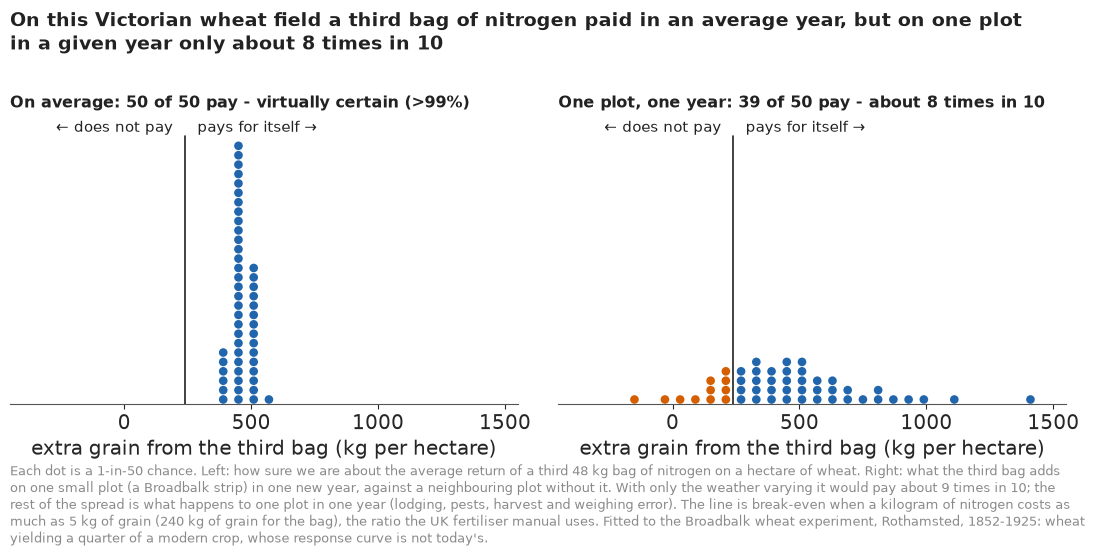

In [26]:
# pub.quantile_dotplot forces an equal aspect, which clips a tall tower of 50 dots next to a wide
# spread on a shared axis, so these local helpers draw the pair
def dot_columns(draws, n, thresh, binw):
    q = np.quantile(np.asarray(draws).ravel(), (np.arange(n) + 0.5) / n)
    col = np.floor((q - thresh) / binw).astype(int)
    xs, ys, cs = [], [], []
    for c in np.unique(col):
        for k, v in enumerate(np.sort(q[col == c])):
            xs.append(thresh + (c + 0.5) * binw)
            ys.append(k + 0.5)
            cs.append(HI if v >= thresh else LO)
    return q, np.array(xs), np.array(ys), cs


def paired_dotplot(axes, draws_list, n=50, thresh=240.0, binw=60.0, xlim=(-450, 1550), top=None):
    """Quantile dotplots on a shared x-axis and shared height, columns aligned on `thresh`."""
    res = [dot_columns(d, n, thresh, binw) for d in draws_list]
    top = top or max(r[2].max() for r in res) + 0.5
    fig = axes[0].figure
    for ax, (q, xs, ys, cs) in zip(axes, res):
        ax.set_xlim(*xlim)
        ax.set_xticks([0, 500, 1000, 1500])  # keeps neighbouring panels' end labels apart
        ax.set_ylim(0, top + 2.4)
        bb = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
        d_pt = min(bb.width * 72 * binw / (xlim[1] - xlim[0]), bb.height * 72 / (top + 2.4)) * 0.92
        ax.scatter(xs, ys, s=d_pt**2, c=cs, linewidths=0, zorder=3)
        ax.plot([thresh, thresh], [0, top + 0.6], color=INK, lw=1.2)
        ax.text(thresh + binw * 0.8, top + 1.4, "pays for itself →", fontsize=10.5,
                va="center", color=INK)
        ax.text(thresh - binw * 0.8, top + 1.4, "← does not pay", fontsize=10.5, va="center",
                ha="right", color=INK)
        ax.set_yticks([])
        for sp in ("left", "right", "top"):
            ax.spines[sp].set_visible(False)
    return [r[0] for r in res], top


AV3, ONE3 = DEC["main"]["avg"][:, 2], DEC["main"]["one"][:, 2]
FREQ10, WEA10 = round(P_ONE * 10), round(P_WEA * 10)
HEAD_TITLE = (f"On this Victorian wheat field a third bag of nitrogen paid in an average year, "
              f"but on one plot in a given year only about {FREQ10} times in 10")
CAPTION = ("Each dot is a 1-in-50 chance. Left: how sure we are about the average return of a "
           "third 48 kg bag of nitrogen on a hectare of wheat. Right: what the third bag adds on "
           "one small plot (a Broadbalk strip) in one new year, against a neighbouring plot "
           f"without it. With only the weather varying it would pay about {WEA10} times in 10; "
           "the rest of the spread is what happens to one plot in one year (lodging, pests, "
           "harvest and weighing error). The line is break-even when a kilogram of nitrogen costs "
           "as much as 5 kg of grain (240 kg of grain for the bag), the ratio the UK fertiliser "
           "manual uses. Fitted to the Broadbalk wheat experiment, Rothamsted, 1852-1925: wheat "
           "yielding a quarter of a modern crop, whose response curve is not today's.")


def headline_figure(R=5, title=HEAD_TITLE, caption=CAPTION, top=None):
    be = BAG * R
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.6), layout="none")
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.27, top=0.78, wspace=0.08)
    (q1, q2), top = paired_dotplot((a1, a2), (AV3, ONE3), thresh=be, top=top)
    k1, k2 = int((q1 >= be).sum()), int((q2 >= be).sum())
    p_av, p_one = np.mean(AV3 > be), np.mean(ONE3 > be)
    pub._title(a1, f"On average: {k1} of 50 pay - {pub.calibrated_word(p_av)} "
                   f"({pub.fmt_pct(p_av)})", fontsize=11.5)
    pub._title(a2, f"One plot, one year: {k2} of 50 pay - about {round(p_one * 10)} times in 10",
               fontsize=11.5)
    for a in (a1, a2):
        a.set_xlabel("extra grain from the third bag (kg per hectare)")
    fig.suptitle(wrap(title, 95), x=0.02, y=0.975, ha="left", va="top", fontsize=14,
                 weight="bold", color=INK)
    fig.text(0.02, 0.015, wrap(caption, 165), fontsize=9.5, color=MUTED, va="bottom")
    return fig, (k1, k2), top


fig_top, _, _ = headline_figure()
HEADLINE.update(fig_top)  # the copy at the top of the notebook
plt.close(fig_top)
_, (K1, K2), TOP = headline_figure()
SURE = pub.how_sure(
    P_AV, "a third 48 kg bag pays for itself in an average year when nitrogen costs 5 kg of grain "
    "per kg", "medium",
    "every curve and model we tried agrees, but each dose was tried on one unreplicated strip, and "
    "this is the wheat and soil of 1852-1925, not of today")
SURE += (f" On any single small plot in a single year it paid about {FREQ10} times in 10 "
         f"({P_ONE:.0%}), a figure that depends on how the model treats plot-to-plot noise.")
HOW_SURE.update(Markdown("**How sure are we.** " + SURE))
print(HEAD_TITLE)
print(f"left: {K1} of 50 dots pay; right: {K2} of 50 dots pay; P(avg) {P_AV:.4f}, "
      f"P(one) {P_ONE:.3f}")
print(SURE)

On the left, all 50 dots stand in a narrow tower well right of the line: we are as sure as a model
can be that the average return clears break-even. On the right, the same bag spreads from a small
loss to over a tonne, and 11 of the 50 dots fall left of the line. Both panels share an axis, so
the tower cannot look dramatic by zooming. The title gives a frequency on a stated unit, "on one
plot in a given year, about 8 times in 10", rather than a likelihood word: "likely" would cover
both 79% and the weather-only 90%. The caption gives the weather-only figure too, and the title
keeps the finding in the past tense, on "this Victorian wheat field".

### Supporting display: each bag, in three kinds of year

The headline is about one bag. The next figure gives the whole ladder as columns of 20 dots
(each a 1-in-20 chance about the *average* return in that kind of year), so the diminishing
returns and the role of the weather are both visible.

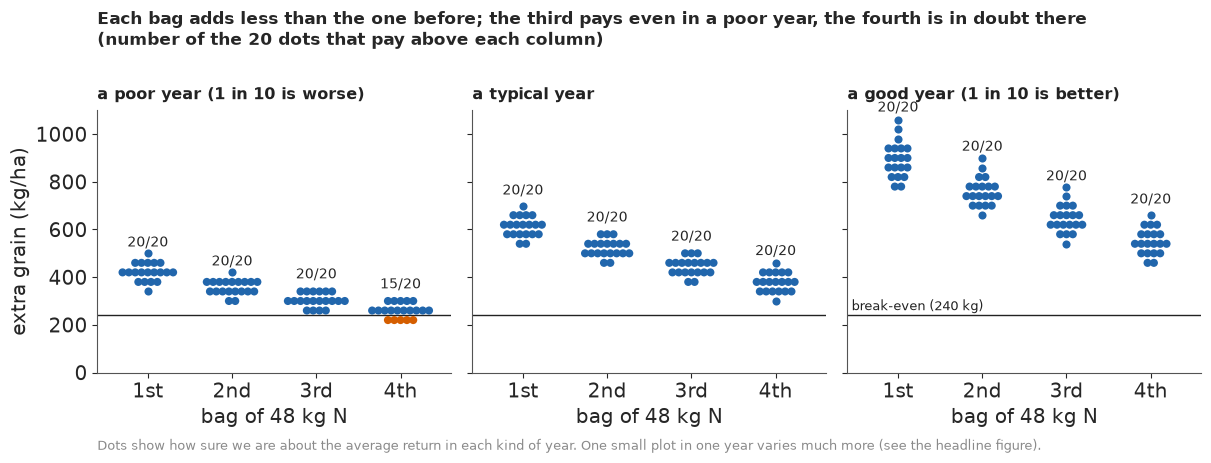

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True, layout="none")
fig.subplots_adjust(left=0.07, right=0.99, top=0.76, bottom=0.19, wspace=0.06)
BINW = 40.0
for ax, (nm, lab) in zip(axes, (("poor", "a poor year (1 in 10 is worse)"),
                                ("typical", "a typical year"),
                                ("good", "a good year (1 in 10 is better)"))):
    a = DEC["main"][nm]
    for j in range(4):
        q = np.quantile(a[:, j], (np.arange(20) + 0.5) / 20)
        row = np.floor((q - 240) / BINW).astype(int)
        for r_ in np.unique(row):
            vals = np.sort(q[row == r_])
            xs = j + 1 + (np.arange(len(vals)) - (len(vals) - 1) / 2) * 0.075
            ax.scatter(xs, np.full(len(vals), 240 + (r_ + 0.5) * BINW), s=34, lw=0,
                       c=[HI if v >= 240 else LO for v in vals], zorder=3)
        ax.text(j + 1, q.max() + 40, f"{int((q >= 240).sum())}/20", ha="center", fontsize=10)
    ax.axhline(240, color=INK, lw=1)
    ax.set_xticks([1, 2, 3, 4], ["1st", "2nd", "3rd", "4th"])
    ax.set_xlim(0.4, 4.6)
    ax.set_ylim(0, 1100)
    ax.set_xlabel("bag of 48 kg N")
    pub._title(ax, lab, fontsize=11.5)
axes[0].set_ylabel("extra grain (kg/ha)")
axes[2].text(0.45, 248, "break-even (240 kg)", ha="left", va="bottom", fontsize=9.5, color=INK)
fig.suptitle(wrap("Each bag adds less than the one before; the third pays even in a poor year, "
                  "the fourth is in doubt there (number of the 20 dots that pay above each "
                  "column)", 110), x=0.07, ha="left", fontsize=12.5)
fig.text(0.07, 0.015, "Dots show how sure we are about the average return in each kind of year. "
         "One small plot in one year varies much more (see the headline figure).", fontsize=9.5,
         color=MUTED, va="bottom");

Read across a panel and the steps get smaller: diminishing returns. Read across the
panels and every column rises with the weather. In a poor year 5 of the fourth bag's 20 dots fall
below the line, while every third-bag dot stays above it, in every kind of year. These dots are
about the average return in each kind of year, so they are narrow; the plot-to-plot noise of the
headline's right panel is not in them.

### The statistician's version, and what the public version gains

The conventional display is the fitted response curve with an 89% band and the data, and the
estimate of interest as a point with an error bar.

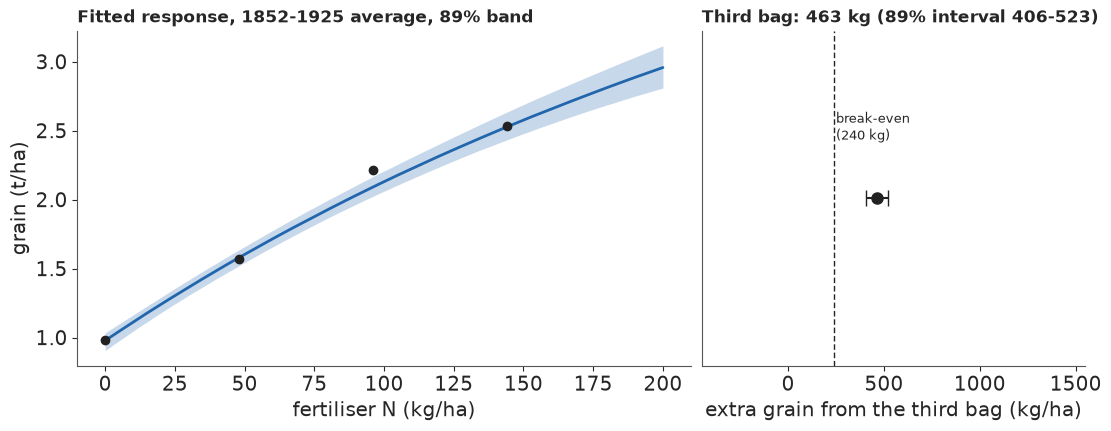

In [28]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1.6, 1]))
NC = np.arange(0, 201.0)
Pm = PM
A_cen = np.exp(Pm["a0"][:, None] + Pm["eta"]).mean(1)  # average over the 74 years
ns_cen = np.mean([soil_n(Pm, y) for y in YEARS], axis=0)
Yc = A_cen[:, None] * (1 - np.exp(-Pm["c"][:, None] * (NC[None, :] / 100 + ns_cen[:, None])))
a1.fill_between(NC, *np.quantile(Yc, [0.055, 0.945], 0), color=HI, alpha=0.25, lw=0)
a1.plot(NC, np.median(Yc, 0), color=HI, lw=2)
a1.scatter(NX, YX, color=INK, zorder=4)
a1.set_xlabel("fertiliser N (kg/ha)")
a1.set_ylabel("grain (t/ha)")
a1.set_title("Fitted response, 1852-1925 average, 89% band", loc="left", fontsize=12)
m3, (l3, h3) = AV3.mean(), np.quantile(AV3, [0.055, 0.945])
a2.errorbar([m3], [0], xerr=[[m3 - l3], [h3 - m3]], fmt="o", color=INK, capsize=6, ms=8)
a2.axvline(240, color=INK, lw=1, ls=(0, (4, 2)))
a2.text(250, 0.35, "break-even\n(240 kg)", fontsize=9.5)
a2.set_xlim(-450, 1550)
a2.set_ylim(-1, 1)
a2.set_yticks([])
a2.set_xlabel("extra grain from the third bag (kg/ha)")
a2.set_title(f"Third bag: {m3:.0f} kg (89% interval {l3:.0f}-{h3:.0f})", loc="left", fontsize=12);

Nothing in this figure is wrong, and for a statistician it is the right summary. But it answers
only the inferential question, and on its own it reads as a promise: "the third bag adds 460 kg".
The paired dotplot keeps the same left-hand fact and adds the plot and year a farmer will
actually have. What it gains is the 8-in-10; what it costs is the curve, so a reader no longer
sees *why* the third bag is worth less than the second. Its pitfall is the unit: the right panel
is one plot, and a farm's chance, pooled over plots that share a year, is higher.

### The price dial

The break-even moves with prices. An animation of the headline over six price ratios, from cheap
nitrogen ($R = 4$) to well past the 2022 spike ($R = 12$), shows the left tower staying put
while the line walks across it, and the right panel's count falling. It is written next to the
notebook as a GIF, as E95 does, with a static companion.

wrote E115_last_bag_of_fertiliser_price_dial.gif: 6 frames, 720x360 px, 0.1 MB
R =  4 (break-even 192 kg): average year 50/50 dots, P = >99%; one year 42/50 dots, P = 85%
R =  5 (break-even 240 kg): average year 50/50 dots, P = >99%; one year 39/50 dots, P = 79%
R =  6 (break-even 288 kg): average year 50/50 dots, P = >99%; one year 36/50 dots, P = 73%
R =  8 (break-even 384 kg): average year 49/50 dots, P = 98%; one year 29/50 dots, P = 57%
R = 10 (break-even 480 kg): average year 16/50 dots, P = 31%; one year 21/50 dots, P = 42%
R = 12 (break-even 576 kg): average year 0/50 dots, P = <1%; one year 14/50 dots, P = 28%


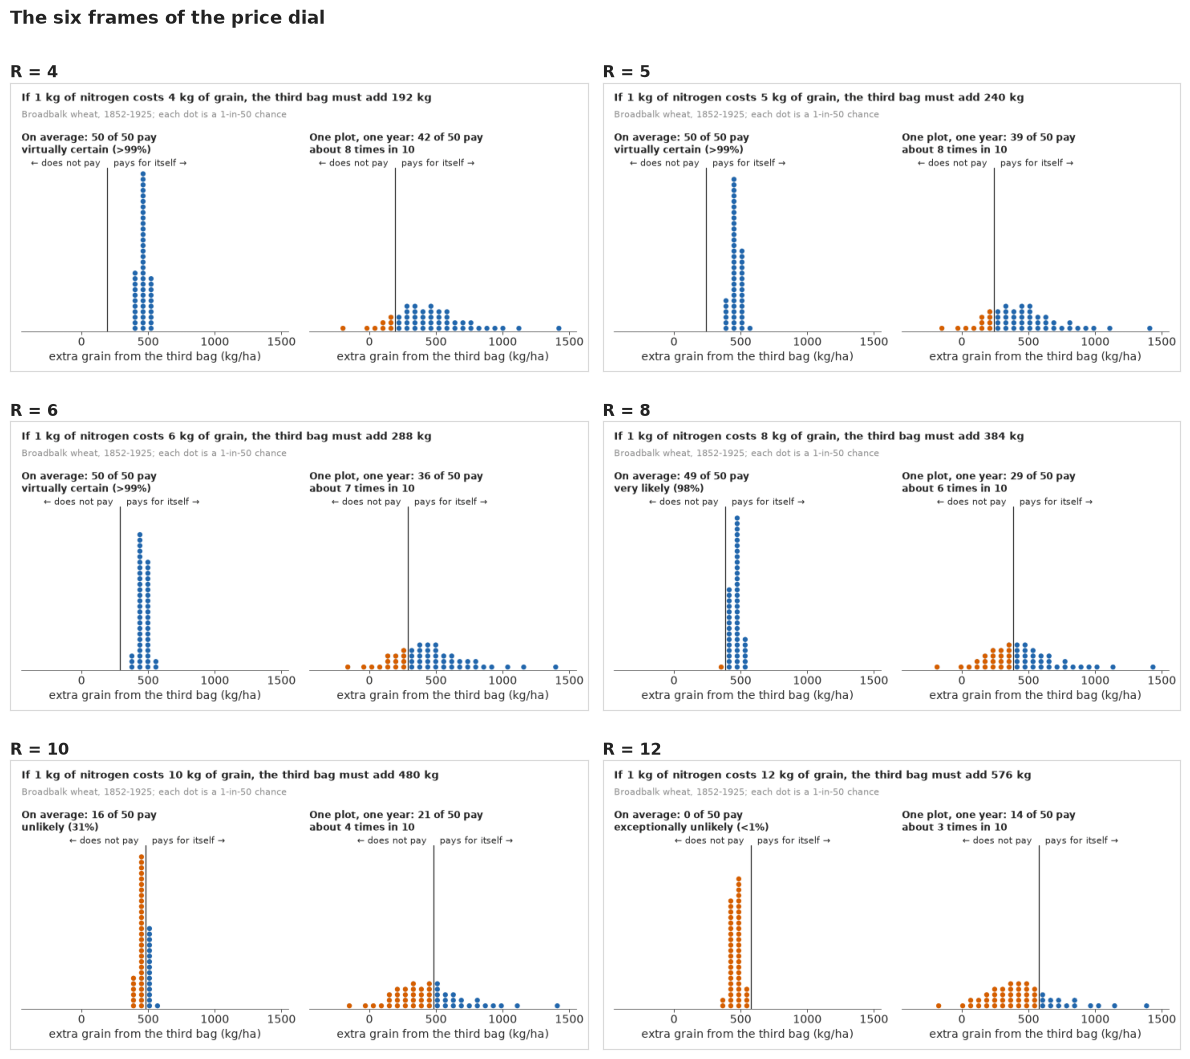

In [29]:
NB_STEM = "E115_last_bag_of_fertiliser"
GIF = f"{NB_STEM}_price_dial.gif"  # the site copies every {stem}*.gif beside the page
fig_g, (g1, g2) = plt.subplots(1, 2, figsize=(10, 5.0), dpi=72, layout="none")
fig_g.subplots_adjust(left=0.02, right=0.98, bottom=0.14, top=0.74, wspace=0.08)
DIAL = []
TOP_D = max(dot_columns(d, 50, BAG * R, 60.0)[2].max() for R in RATIOS for d in (AV3, ONE3)) + 0.5


def dial_frame(k):
    R = RATIOS[k]
    be = BAG * R
    for a in (g1, g2):
        a.clear()
    (q1, q2), _ = paired_dotplot((g1, g2), (AV3, ONE3), thresh=be, xlim=(-450, 1550), top=TOP_D)
    k1, k2 = int((q1 >= be).sum()), int((q2 >= be).sum())
    p_av, p_one = np.mean(AV3 > be), np.mean(ONE3 > be)
    DIAL.append((R, k1, k2, p_av, p_one))
    g1.set_title(f"On average: {k1} of 50 pay\n{pub.calibrated_word(p_av)} ({pub.fmt_pct(p_av)})",
                 loc="left", fontsize=12, color=INK)
    g2.set_title(f"One plot, one year: {k2} of 50 pay\nabout {round(p_one * 10)} times in 10",
                 loc="left", fontsize=12, color=INK)
    for a in (g1, g2):
        a.set_xlabel("extra grain from the third bag (kg/ha)")
    fig_g.texts.clear()
    fig_g.text(0.02, 0.965, f"If 1 kg of nitrogen costs {R} kg of grain, the third bag must add "
               f"{be} kg", fontsize=13, weight="bold", color=INK, va="top")
    fig_g.text(0.02, 0.905, "Broadbalk wheat, 1852-1925; each dot is a 1-in-50 chance",
               fontsize=10.5, color=MUTED, va="top")


t0 = time.time()
frames = pub.save_gif(fig_g, dial_frame, len(RATIOS), GIF, ms=1600, first_ms=2400, last_ms=3200)
plt.close(fig_g)
TIMES["GIF"] = time.time() - t0
for R, k1, k2, p_av, p_one in DIAL:
    print(f"R = {R:>2} (break-even {BAG * R} kg): average year {k1}/50 dots, "
          f"P = {pub.fmt_pct(p_av)}; one year {k2}/50 dots, P = {p_one:.0%}")
pub.gif_contact_sheet(frames, captions=[f"R = {R}" for R in RATIOS],
                      title="The six frames of the price dial");

The animation is saved as
[E115_last_bag_of_fertiliser_price_dial.gif](E115_last_bag_of_fertiliser_price_dial.gif); the six
frames above are its static companion.

![Animated paired dotplots of the extra grain from a third bag of nitrogen at six prices: on the
left a narrow tower of 50 dots near 460 kg, on the right a wide spread; as nitrogen gets dearer
the break-even line moves right from 192 to 576 kg, the tower stays on the paying side until the
line passes it at the dearest prices, and the count of paying dots on the right falls
steadily](E115_last_bag_of_fertiliser_price_dial.gif)

At cheap nitrogen every average-year dot pays and about 8 in 10 one-plot dots do. At $R = 8$ the
line reaches the tower's edge and the left-hand verdict drops to *very likely* (98%), at 10 to
*unlikely* (31%), while the right-hand count slides from 42 to 14 of 50: the average-year answer
is a cliff, because we know it precisely, and the one-plot answer a slope, because one plot in one
year, weather and all, varies so much. That asymmetry is the reason to show both.

In [30]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'naive': 27, 'Liebig minimum': 26, 'partial Liebig': 27, 'main': 97, 'quadratic-plateau': 82, 'sharp linear-plateau': 31, 'GIF': 1, 'total': 299}


## Summary

- **The record carries three things at once**: a dose response (strips 5-8 gain about 590, 650
  and 310 kg per extra 48 kg bag), a year that lifts or sinks the whole field (year sd about 0.29
  on the log scale, little persistence, 1912 the worst at about two fifths of an average year),
  and slow soil change (the soil's own nitrogen falls from about 90 kg/ha-equivalent towards 46
  over decades). With one strip per dose, strip 7's soil (about 5% above average) cannot be told
  from an S-shaped response.
- **Liebig was half right.** A literal law of the minimum lost about 130 points of elpd to a
  plain multiplier, because minerals matter even without nitrogen; a partial version, in which
  a missing nutrient bites harder on a well-fed crop, gained about 16. Missing potassium cost
  about a fifth of the yield in the 1850s and a third by the 1920s (without strip effects).
- **Averages can fit while the spread is wrong.** Every treatment mean matched, yet the replayed
  yearly increments of strips 5-8 were about twice as spread out as the real ones (third bag IQR
  about 630 against 315 kg). Strip effects, a year-by-dose term and a noise scale per strip fixed
  it and gained about 260 points of elpd. Neighbouring well-fed strips still share part of their
  yearly luck (residual correlation about +0.4).
- **The third bag paid on average, not every year.** At a price ratio of 5 it added about 460 kg
  (89%: 405-525) in an average year, *virtually certain* to clear 240 kg, given the curve and the
  strip effects, and robust to curve, model and prior. In a fresh year it paid about 90% of the
  time with the weather alone and 79% on one plot; the replay of strips 8 and 7 brackets their
  61%. Models with one pooled noise scale gave 60-63%: the one-plot figure depends on the noise.
- **The optimum N rate is mostly the curve.** At ratio 5 it lies beyond the 192 kg ever tested,
  about 315 kg under Mitscherlich and 380 under the quadratic-plateau, which LOO cannot separate
  (about 2 ± 1 points); a wider curvature prior moves it by 25-60 kg. A sharp linear-plateau split
  its chains (r_hat 1.64, ESS 7, zero divergences).
- **The fourth bag is unsettled.** The models say it pays on average; strip 16's 13 years gained
  about 2%, which the main model puts mostly down to those years, partly to a poorer strip.
- **Show prediction beside inference, on a stated unit.** The same bag was >99% on average and 8
  in 10 on one plot in one year, 9 in 10 with the weather alone, so the unit belongs in the title.
  Displays: paired 50-dot quantile dotplots, dotplot columns per bag and kind of year, gradient
  strips for the optimum, a price-dial GIF, and the fitted curve with an error bar as contrast.

## Try it yourself

1. **Weather you can measure.** The `agridat` package also has Minnesota barley yields with
   monthly weather (`minnesota.barley.yield` and `minnesota.barley.weather`). Replace the latent
   year potential by a regression on rainfall and temperature plus a smaller latent remainder,
   and see how much of the one-year spread a farmer could know in advance.
2. **Weather that the dose feels.** Here the year-by-dose terms are independent of the ceiling.
   Correlate them with $\eta_t$, and ask whether the third bag is worth relatively more in good
   years, as agronomists often claim; or let neighbouring strips share noise within a year.
3. **How many strips would Fisher have needed?** Simulate a replicated Broadbalk from the main
   posterior: two, three or four strips per treatment with fresh strip effects, refit, and find
   how many replicates it takes to say whether the fourth bag pays, the question one strip left
   open.